In [2]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'  # убирает системное предупреждение joblib в Windows при запуске KMeans
import kagglehub
import pandas as pd
import os
import warnings
import numpy as np
warnings.filterwarnings('ignore')
import re
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import time
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from mpl_toolkits.mplot3d import Axes3D
from wordcloud import WordCloud
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import SGDClassifier, RidgeClassifier, Perceptron
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


# Классификация новостных текстов по тематике с использованием методов семантического анализа и ансамблевых моделей

**Цель работы**: построить модель, которая по тексту новости (заголовок + краткое описание) автоматически определяет к какой теме следует ее отнести. Это классическая задача **многоклассовой классификации текстов с учителем**.

**Практическая ценность:** автоматическая классификация новостных лент, рекомендательные системы, фильтрация по интересам пользователя, анализ медиа-трендов

## 1. Датасет

В работе используется **News Category Dataset** (автор - Rishabh Misra), опубликованный на Kaggle. Данные собраны с новостного агрегатора **HuffPost** и охватывают период 2012–2022 гг. Загрузим данные напрямую с Kaggle.

In [3]:
path = kagglehub.dataset_download("rmisra/news-category-dataset")
file_path = os.path.join(path, "News_Category_Dataset_v3.json")
df = pd.read_json(file_path, lines=True)

100%|██████████| 26.5M/26.5M [00:36<00:00, 772kB/s] 

Extracting files...


In [4]:
df.head()

,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [5]:
df.shape

(209527, 6)

Каждая запись датасета содержит следующие поля:
- **`link`** - ссылка на оригинал на сайте HuffPost;
- **`headline`** - заголовок новости;
- **`category`** - тематическая рубрика новости (целевая переменная);
- **`short_description`** - краткое описание;
- **`authors`** - авторы статьи;
- **`date`** - дата публикации.

Датасет содержит 209527 строк и 6 столбцов (полей)

Выведем количество строк, относящихся к каждой из категорий

In [6]:
print(df['category'].value_counts())

category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3572
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2104
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1444
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ARTS & CULTURE     1339
COLLEGE            1144
LATINO VOICES      1130
CULTURE & ARTS     1074
EDUCATI

Для наглядности выведем ту же информацию в процентах

In [7]:
print(len(df['category'].unique()))
print((df['category'].value_counts() / df.shape[0] * 100).round(2).astype(str) + " %")

42
category
POLITICS          16.99 %
WELLNESS           8.56 %
ENTERTAINMENT      8.29 %
TRAVEL             4.72 %
STYLE & BEAUTY     4.68 %
PARENTING           4.2 %
HEALTHY LIVING     3.19 %
QUEER VOICES       3.03 %
FOOD & DRINK       3.03 %
BUSINESS           2.86 %
COMEDY             2.58 %
SPORTS             2.42 %
BLACK VOICES       2.19 %
HOME & LIVING      2.06 %
PARENTS            1.89 %
THE WORLDPOST      1.75 %
WEDDINGS           1.74 %
WOMEN               1.7 %
CRIME               1.7 %
IMPACT             1.66 %
DIVORCE            1.64 %
WORLD NEWS         1.57 %
MEDIA              1.41 %
WEIRD NEWS         1.33 %
GREEN              1.25 %
WORLDPOST          1.23 %
RELIGION           1.23 %
STYLE              1.08 %
SCIENCE            1.05 %
TECH                1.0 %
TASTE               1.0 %
MONEY              0.84 %
ARTS               0.72 %
ENVIRONMENT        0.69 %
FIFTY              0.67 %
GOOD NEWS          0.67 %
U.S. NEWS          0.66 %
ARTS & CULTURE     0.64 %


В исходном датасете 42 категории, однако они распределены крайне неравномерно: от POLITICS (~17% всех записей) до совсем редких классов (менее 0.5%). Кроме того, среди категорий есть **семантически дублирующиеся** (например, `WORLDPOST` и `THE WORLDPOST`, `ARTS` и `ARTS & CULTURE`), которые фактически описывают одну и ту же тему.

Работа с 42 классами одновременно нецелесообразна: часть классов будет содержать слишком мало примеров для обучения, а а наличие семантических дублей будет искусственно занижать качество модели. Поэтому далее выполним объединение близких категорий и отбор наиболее представительных классов

Категории, которые можно объединить

- WORLDPOST + THE WORLDPOST + WORLD NEWS = WORLD NEWS (Мировые новости)

- ARTS + ARTS & CULTURE + CULTURE & ARTS = ARTS & CULTURE (Искусство и культура)

- PARENTS + PARENTING = PARENTING (Родительство и воспитание детей)

- STYLE + STYLE & BEAUTY = STYLE & BEAUTY (Стиль и мода)

- HEALTHY LIVING + WELLNESS = WELLNESS (Здоровый образ жизни и благополучие)

- TASTE + FOOD & DRINK = FOOD & DRINK (Еда и напитки)

- GREEN + ENVIRONMENT = ENVIRONMENT (Экология)

- COLLEGE + EDUCATION = EDUCATION (Образование)


Помимо объединения дубликатов, исключим из датасета категории `BLACK VOICES`, `LATINO VOICES`, `QUEER VOICES` и `WOMEN`. В отличие от остальных рубрик, они определяются не тематикой материала, а целевой аудиторией, к которой этот материал обращен. Внутри таких категорий могут находиться статьи на любую тему от политики до культуры и спорта, что делает их пересекающимися со всеми остальными классами и препятствует корректному построению границ решений.

In [8]:
df['category'] = df['category'].replace(['WORLDPOST', 'THE WORLDPOST', 'WORLD NEWS'], 'WORLD NEWS')
df['category'] = df['category'].replace(['ARTS', 'ARTS & CULTURE', 'CULTURE & ARTS'], 'ARTS & CULTURE')
df['category'] = df['category'].replace(['PARENTS', 'PARENTING'], 'PARENTING')
df['category'] = df['category'].replace(['STYLE', 'STYLE & BEAUTY'], 'STYLE & BEAUTY')
df['category'] = df['category'].replace(['HEALTHY LIVING', 'WELLNESS'], 'WELLNESS')
df['category'] = df['category'].replace(['TASTE', 'FOOD & DRINK'], 'FOOD & DRINK')
df['category'] = df['category'].replace(['GREEN', 'ENVIRONMENT'], 'ENVIRONMENT')
df['category'] = df['category'].replace(['COLLEGE', 'EDUCATION'], 'EDUCATION')

df.drop(df[df['category'] == 'BLACK VOICES'].index, inplace=True)
df.drop(df[df['category'] == 'LATINO VOICES'].index, inplace=True)
df.drop(df[df['category'] == 'QUEER VOICES'].index, inplace=True)
df.drop(df[df['category'] == 'WOMEN'].index, inplace=True)

print(len(df['category'].unique()))
print(df['category'].value_counts())

28
category
POLITICS          35602
WELLNESS          24639
ENTERTAINMENT     17362
PARENTING         12746
STYLE & BEAUTY    12068
TRAVEL             9900
WORLD NEWS         9542
FOOD & DRINK       8436
BUSINESS           5992
COMEDY             5400
SPORTS             5077
HOME & LIVING      4320
ENVIRONMENT        4066
ARTS & CULTURE     3922
WEDDINGS           3653
CRIME              3562
IMPACT             3484
DIVORCE            3426
MEDIA              2944
WEIRD NEWS         2777
RELIGION           2577
SCIENCE            2206
EDUCATION          2158
TECH               2104
MONEY              1756
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
Name: count, dtype: int64


Далее необходимо выделить несколько наиболее представленных по объёму категорий, и на их основе сформировать сбалансированную выборку. В таблицах опишем, какие категории стоит/не стоит оставлять и почему.

| Категория      | Кол-во записей | Почему стоит оставить                              |
|----------------|---------------|-------------------------------------------|
| POLITICS       | 35602         | Классическая новостная тематика, крупнейший класс в датасете              |
| ENTERTAINMENT  | 17362         | Специфичная лексика (фильмы, шоу, знаменитости), хорошо отличимая от остальных классов|
| TRAVEL         | 9900          | Ярко выраженная тематическая лексика (направления, отели, транспорт)                |
| BUSINESS       | 5992          | Стандартная новостная рубрика с устойчивой экономической терминологией   |
| SPORTS         | 5077          | Узкая специализированная лексика (команды, игроки, турниры)         |
| SCIENCE        | 2206          | Характерная научная лексика         |
| TECH           | 2104          | Технологическая терминология, близкая к SCIENCE, но с отличным словарем |
| CRIME          | 3562          | Характерная юридическая/криминальная лексика               |

| Категория                                      | Причина исключения                                                                 |
|--------------------------------------------------|------------------------------------------------------------------------------------|
| WELLNESS, PARENTING, STYLE & BEAUTY, HOME & LIVING, WEDDINGS, DIVORCE | Относятся преимущественно к лайфстайл-контенту и слабо соответствуют новостной тематике |
| COMEDY, WEIRD NEWS, GOOD NEWS                    | Определяются форматом или тоном подачи, а не предметной областью                   |
| FOOD & DRINK                                     | Частично пересекается с другими категориями (например, TRAVEL) по используемой лексике |
| WORLD NEWS                                       | Существенно пересекается с категорией POLITICS по содержанию                       |
| IMPACT, FIFTY, MEDIA, RELIGION                  | Характеризуются размытыми границами или недостаточным объемом данных               |

Оставляем выбранные категории и выводим распределение строк для каждой из них

In [9]:
categories = ['POLITICS', 'ENTERTAINMENT', 'TRAVEL', 'BUSINESS', 'SPORTS', 'SCIENCE', 'TECH', 'CRIME']
df = df[df['category'].isin(categories)]
print(df['category'].value_counts())

category
POLITICS         35602
ENTERTAINMENT    17362
TRAVEL            9900
BUSINESS          5992
SPORTS            5077
CRIME             3562
SCIENCE           2206
TECH              2104
Name: count, dtype: int64


Распределение записей по отобранным категориям является существенно неравномерным: класс POLITICS содержит около 35 000 записей, тогда как классы SCIENCE и TECH  порядка 2 000. Обучение модели на несбалансированных данных привело бы к смещению предсказаний в сторону доминирующего класса и снижению качества распознавания редких категорий.

Для устранения дисбаланса применим стратегия **undersampling**: из каждого класса случайным образом отбирается не более 5 000 записей (либо все имеющиеся, если их меньше).

Применение данной процедуры обосновано следующими соображениями:
- снижается риск получения модели, систематически предсказывающей мажоритарный класс;
- обеспечивается равный вклад каждой категории в функцию потерь при обучении


In [10]:
df = df.groupby('category').apply(lambda x: x.sample(min(5000, len(x)), random_state=0))
df = df.reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32872 entries, 0 to 32871
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   link               32872 non-null  object        
 1   headline           32872 non-null  object        
 2   category           32872 non-null  object        
 3   short_description  32872 non-null  object        
 4   authors            32872 non-null  object        
 5   date               32872 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 1.5+ MB


Итоговый объем выборки составляет **32 872** строки. Пропуски в данных отсутствуют. Все используемые в дальнейшем признаки являются текстовыми (тип `object`), целевая переменная `category` - категориальной. Полученный объем является достаточным для обучения классических моделей машинного обучения без риска переобучения.

In [11]:
print((df['category'].value_counts() / df.shape[0] * 100).round(2).astype(str) + " %")

category
BUSINESS         15.21 %
ENTERTAINMENT    15.21 %
POLITICS         15.21 %
SPORTS           15.21 %
TRAVEL           15.21 %
CRIME            10.84 %
SCIENCE           6.71 %
TECH               6.4 %
Name: count, dtype: object


Итоговое распределение классов приобретает следующий вид: пять категорий (BUSINESS, ENTERTAINMENT, POLITICS, SPORTS, TRAVEL) представлены в равных долях по 15.21 %, категория CRIME составляет 10.84 %, категории SCIENCE и TECH - 6.71 % и 6.40 % соответственно.

Несмотря на то, что идеальная сбалансированность не достигнута, степень неравномерности существенно снижена по сравнению с исходным распределением.

Важно учитывать: балансировка выполнена до разбиения на обучающую и тестовую выборки, поэтому тестовая выборка тоже сбалансирована. Значит, итоговые метрики описывают качество на сбалансированном наборе новостей, а в реальном потоке, где POLITICS занимает около 44% новостей выбранных рубрик, они могут отличаться.

## 2. Предварительный анализ и очистка данных

Перед построением классификатора необходимо обосновать выбор входных признаков. Исходный датасет содержит шесть полей, которые по отношению к целевой переменной `category` можно разделить на три группы:

1. **Семантически значимые признаки** - `headline` и `short_description`. Именно лексический состав заголовка и краткого описания определяет тематическую принадлежность новости и является основой для классификации. Эти поля содержат естественно-языковое описание содержания статьи и будут использованы в качестве входных данных модели.

2. **Потенциально значимые, но отбрасываемые признаки** - `authors` и `date`. Теоретически сведения об авторе могут коррелировать с тематикой (один и тот же журналист чаще пишет на определённые темы), а дата публикации с актуальными событиями соответствующего периода. Однако использование этих признаков привело бы к утечке мета-информации, не связанной с содержанием текста, и к ухудшению обобщающей способности модели на новых данных (где авторы и даты могут отсутствовать или отличаться). Кроме того, это противоречит задаче **семантического анализа**, которая решается в этом проекте.

3. **Технические признаки** - `link`. Содержит URL статьи на сайте HuffPost, не имеет самостоятельного содержательного смысла и не используется в работе.

Таким образом, для обучения модели используется только объединение двух текстовых полей: `headline` и `short_description`.


Поля `headline` и `short_description` объединим в единый признак `text`, чтобы модель оперировала более полным контекстом каждой новости. Заголовки, взятые изолированно, зачастую слишком коротки и могут быть неоднозначными, тогда как краткое описание добавляет конкретные детали содержания.

Одновременно с этим из датафрейма удалим неиспользуемые поля (`link`, `authors`, `date`, а также исходные `headline` и `short_description`, заменённые на объединённый признак).

Еще раз посмотрим на поля таблицы до:

In [12]:
df.head()

,link,headline,category,short_description,authors,date
0,https://www.huffingtonpost.com/entry/women-in-...,"Women in Business Q&A: Jeni Garrett, CEO and F...",BUSINESS,Jeni Garrett was only 21 years old when she op...,"Laura Dunn, ContributorSocial Media and Commun...",2014-12-27
1,https://www.huffingtonpost.com/entry/volkswage...,FBI Arrests Volkswagen Executive In Emissions ...,BUSINESS,"Oliver Schmidt, who oversaw the automaker's re...",,2017-01-09
2,https://www.huffingtonpost.com/entry/zombie-ap...,Zombie Apocalypse Product Guide: CNBC,BUSINESS,"In this way, the zombie apocalypse has already...",,2012-10-20
3,https://www.huffingtonpost.com/entry/meeting-n...,Meeting Notes and the Hearsay Rule,BUSINESS,"If one is inclined to make notes of meetings, ...","Brad Reid, Contributor\nSenior Scholar, Dean I...",2014-01-20
4,https://www.huffingtonpost.com/entry/racial-we...,Black-White Wealth Gap Has Reached A 24-Year High,BUSINESS,,Alexander C. Kaufman,2014-12-13


И после удаления ненужных столбцов и объединения заголовка и описания новости:

In [13]:
df['text'] = df['headline'] + ' ' + df['short_description']
df.drop(['headline', 'short_description', 'link', 'authors', 'date'], axis=1, inplace=True)

df.head()

,category,text
0,BUSINESS,"Women in Business Q&A: Jeni Garrett, CEO and F..."
1,BUSINESS,FBI Arrests Volkswagen Executive In Emissions ...
2,BUSINESS,Zombie Apocalypse Product Guide: CNBC In this ...
3,BUSINESS,Meeting Notes and the Hearsay Rule If one is i...
4,BUSINESS,Black-White Wealth Gap Has Reached A 24-Year H...


В результате рабочая структура данных включает только два столбца: целевую переменную `category` и входной текстовый признак `text`.

Также необходимо проверить данные на наличие дубликатов. Их наличие в обучающей выборке нежелательно, потому что они искусственно завышают метрики качества, если одинаковые примеры попадают одновременно в обучающую и тестовую выборки (data leakage). Также они смещают обучение в сторону повторяющихся паттернов, не повышая реального разнообразия данных. При наличии удалим строки с дубликатами.

In [14]:
print(df.duplicated(subset='text').sum())

58


In [15]:
df.drop_duplicates(subset='text', inplace=True)
df.reset_index(drop=True, inplace=True)

Для понимания структуры данных вычислим описательные статистики длин текстовых записей (в символах): минимум, максимум, среднее, медиана и квартили. С помощью этой информации можно выявить потенциальные аномалии, например, слишком короткие записи, не несущие содержательной информации, либо экстремально длинные, требующие отдельной обработки.

In [16]:
df['text'].apply(lambda x: len(x)).describe()

count    32814.000000
mean       164.530018
std         78.214483
min          1.000000
25%        111.000000
50%        162.000000
75%        201.000000
max       1183.000000
Name: text, dtype: float64

Средняя длина текста составляет около 165 символов, а медианное значение - 162 символа, что говорит о близости распределения к симметричному.

При этом наблюдается достаточно большой разброс значений (стандартное отклонение ~78), что указывает на неоднородность выборки по длине текстов.

Минимальное значение равно 1 символу, что говорит о наличии некорректных или пустых записей, тогда как максимальная длина достигает 1183 символов.

Квартильные значения (111, 162 и 201) показывают, что основная масса текстов сосредоточена в диапазоне от 100 до 200 символов.

Сделаем дополнительный анализ 100 наиболее коротких текстов, отсортировав выборку по возрастанию длины

In [17]:
df['text_length'] = df['text'].apply(len)
df_sorted_by_length = df.sort_values(by='text_length', ascending=True)
print('Самые короткие тексты:')
for index, row in df_sorted_by_length.head(100).iterrows():
    print(f"Длина: {row['text_length']}, Текст: {row['text']}")

df.drop(columns=['text_length'], inplace=True)

Самые короткие тексты:
Длина: 1, Текст:  
Длина: 4, Текст: CUT 
Длина: 4, Текст: MEH 
Длина: 7, Текст: SPLIT! 
Длина: 8, Текст: AHHHHHH 
Длина: 9, Текст: BANKRUPT 
Длина: 10, Текст: Kiss FAIL 
Длина: 11, Текст: The Future 
Длина: 12, Текст: KNOCKED OUT 
Длина: 13, Текст: OUT IN FRONT 
Длина: 13, Текст: They're Back 
Длина: 14, Текст: Safety Off... 
Длина: 15, Текст: DOWN AND DIRTY 
Длина: 15, Текст: Down the drain 
Длина: 15, Текст: It'll Be Grand 
Длина: 15, Текст: Speech & Money 
Длина: 15, Текст: Men of Tai Chi 
Длина: 15, Текст: NFL Scoreboard 
Длина: 15, Текст: Brand As Human 
Длина: 15, Текст: Hagel Farewell 
Длина: 16, Текст: Mixed prognosis 
Длина: 16, Текст: They're Coming! 
Длина: 16, Текст: Obama Unleashed 
Длина: 16, Текст: The Wonder Drug 
Длина: 17, Текст: A-Rod Apologizes 
Длина: 17, Текст: Southwest Shares 
Длина: 17, Текст: The Obama Effect 
Длина: 17, Текст: Cruising Bermuda 
Длина: 17, Текст: Ready To Rumble? 
Длина: 17, Текст: Minnesota Music! 
Длина: 17, Текст: The

Cреди коротких текстов преобладают записи длиной менее 25 символов, обрывки заголовков без описания или одиночные слова. Такие записи не обладают достаточной информативностью для корректной тематической классификации и могут вносить шум в обучение модели.

Выполним фильтрацию данных, оставив только тексты длиной не менее 50 символов. Это позволит исключить нерелевантные и малосодержательные записи и повысить качество последующего анализа и обучения модели

In [18]:
df = df[df['text'].str.len() >= 50]

In [19]:
df['text'].apply(lambda x: len(x)).describe()

count    31404.000000
mean       170.145491
std         75.201623
min         50.000000
25%        118.000000
50%        165.000000
75%        204.000000
max       1183.000000
Name: text, dtype: float64

Для приведения текстов к единому виду, пригодному для векторизации методом TF-IDF, выполняется последовательная предобработка, включающая следующие операции:

1. **Приведение к нижнему регистру** - устраняет различие между одинаковыми словами в разной форме записи.
2. **Удаление неалфавитных символов** - с помощью регулярного выражения отбрасываются цифры, знаки препинания, специальные символы и любые иные элементы, не несущие семантической нагрузки для тематической классификации.
3. **Токенизация** - разбиение текста на отдельные слова (токены) при помощи инструмента `word_tokenize` из библиотеки NLTK.
4. **Удаление стоп-слов** - исключаются высокочастотные служебные слова английского языка (`the`, `a`, `is`, `of` и др.), которые встречаются во всех тематиках с примерно одинаковой частотой и не несут различающей информации.
5. **Лемматизация** - приведение слов к их словарной форме с помощью `WordNetLemmatizer`. Например, формы `running`, `ran`, `runs` будут заменены на единую лемму `run`, что повышает согласованность признакового пространства и снижает его размерность без потери смысла.

Такой набор преобразований является стандартным для задач классической обработки текстов и соответствует методам семантического анализа.

In [20]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
  text = text.lower()
  text = re.sub(r'[^a-z\s]', '', text)
  text = word_tokenize(text)
  text = [lemmatizer.lemmatize(word) for word in text if word not in stop_words]

  return ' '.join(text)

In [21]:
df['text'] = df['text'].apply(clean_text)

In [22]:
df['text'].head()

0    woman business qa jeni garrett ceo founder woo...
1    fbi arrest volkswagen executive emission scand...
2    zombie apocalypse product guide cnbc way zombi...
3    meeting note hearsay rule one inclined make no...
4              blackwhite wealth gap reached year high
Name: text, dtype: object

Завершая этап очистки и нормализации данных, выведем информацию о пропусках в данных и о размере выборки

In [23]:
print('Пропуски по столбцам:')
print(df.isnull().sum())

Пропуски по столбцам:
category    0
text        0
dtype: int64


In [24]:
print(f'Итоговый размер выборки после очистки: {df.shape}')

Итоговый размер выборки после очистки: (31404, 2)


После завершения всех операций очистки и нормализации рабочая выборка содержит 31404 записи в двух столбцах: целевой переменной `category` и нормализованном текстовом признаке `text`. Представленные примеры демонстрируют итоговую структуру данных, готовую для последующего этапа разведочного анализа и векторизации.

## 3. EDA с графиками

На данном этапе выполним исследование структуры данных посредством визуализации распределений признаков и анализа их связи с целевой переменной. Цель этапа - получить содержательное представление о данных, выявить потенциальные аномалии, оценить разделимость классов и сформировать обоснованные решения о дальнейшей обработке.

**Специфика EDA для текстовых данных**

Классический набор методов разведочного анализа (корреляционные матрицы, проверка на нормальность) разработан для числовых признаков и неприменим к исходным данным настоящей работы напрямую, поскольку единственным содержательным признаком является текстовое поле `text`. В связи с этим анализ адаптируем к природе данных и включим:
- анализ распределения целевой переменной;
- анализ количественных характеристик текстов (длина в символах и словах);
- анализ частотных характеристик лексики в целом и по классам;
- оценку лексического пересечения классов как меры их потенциальной смешиваемости.

Построение корреляционной матрицы между признаками в классическом виде невозможно; в качестве альтернативы анализ связей с целевой переменной произведем через характерные слова каждого класса, что является стандартным подходом в области обработки естественного языка.

**Анализ распределения целевой переменной:**

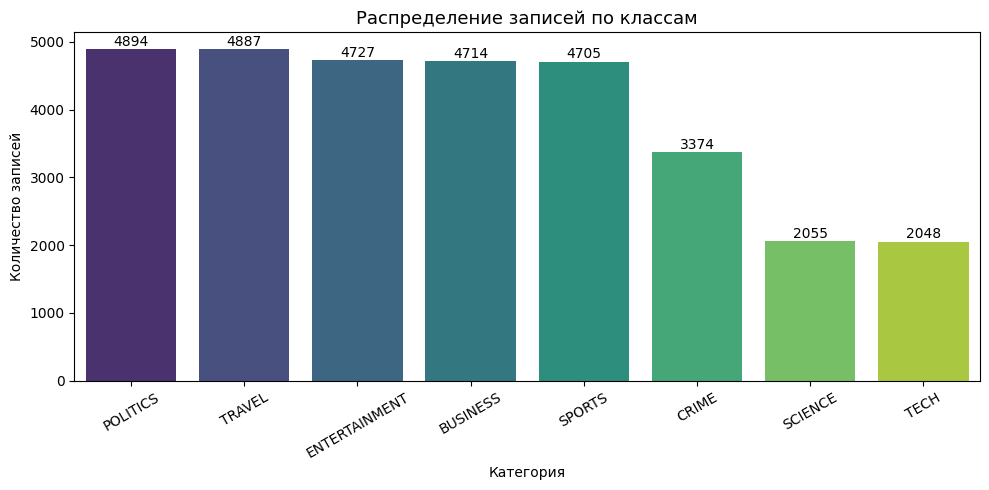

In [25]:
plt.figure(figsize=(10, 5))
class_counts = df['category'].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Распределение записей по классам', fontsize=13)
plt.xlabel('Категория')
plt.ylabel('Количество записей')
plt.xticks(rotation=30)
for i, v in enumerate(class_counts.values):
    plt.text(i, v + 50, str(v), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

Визуализация подтверждает результаты балансировки, выполненной на предыдущем этапе: пять классов (BUSINESS, ENTERTAINMENT, POLITICS, SPORTS, TRAVEL) представлены равным объемом записей, соответствующим установленному порогу в 5000 документов. Классы CRIME, SCIENCE и TECH содержат меньшее число записей, определяемое их исходным объёмом в датасете. Остаточный дисбаланс не превышает соотношения 2.5:1 и не требует применения дополнительных методов балансировки

**Анализ распределения длин текстов (в символах, после очистки):**

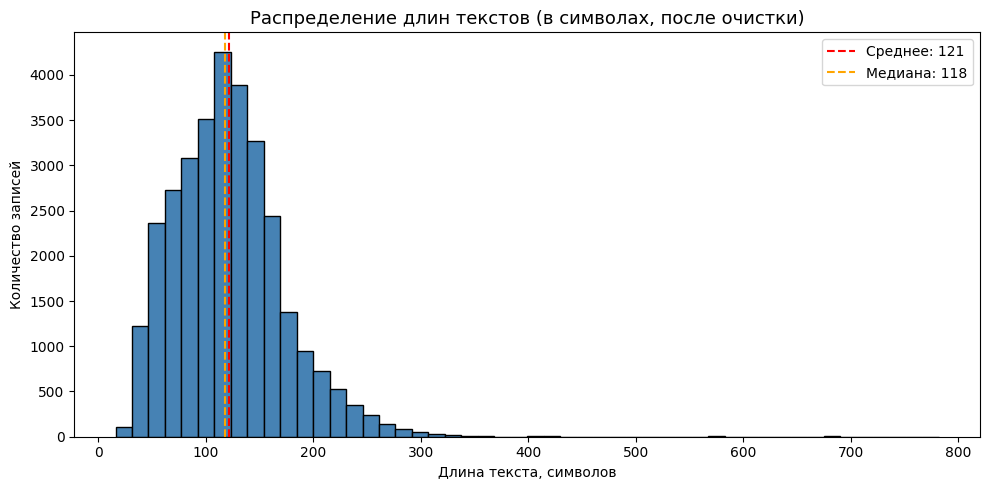

count    31404.0
mean       121.2
std         51.7
min         16.0
25%         85.0
50%        118.0
75%        149.0
max        782.0
Name: char_length, dtype: float64


In [26]:
df['char_length'] = df['text'].apply(len)

plt.figure(figsize=(10, 5))
plt.hist(df['char_length'], bins=50, color='steelblue', edgecolor='black')
plt.axvline(df['char_length'].mean(), color='red', linestyle='--',
            label=f'Среднее: {df["char_length"].mean():.0f}')
plt.axvline(df['char_length'].median(), color='orange', linestyle='--',
            label=f'Медиана: {df["char_length"].median():.0f}')
plt.title('Распределение длин текстов (в символах, после очистки)', fontsize=13)
plt.xlabel('Длина текста, символов')
plt.ylabel('Количество записей')
plt.legend()
plt.tight_layout()
plt.show()

print(df['char_length'].describe().round(1))

Распределение длин текстов после нормализации характеризуется правосторонней асимметрией. Среднее значение (121.2 символа) превышает медиану (118 символов), а стандартное отклонение (51.7) сопоставимо со средним, что свидетельствует о значительном разбросе длин. Центральные 50 % записей (межквартильный размах) сосредоточены в диапазоне от 85 до 149 символов, тогда как максимальное значение достигает 782 символов, формируя вытянутый правый «хвост» распределения. Данные признаки характерны для несимметричных распределений и указывают на неприменимость предположения о нормальности.

Минимальная длина текста составляет 16 символов, что ниже установленного ранее порога в 50 символов. Это объясняется тем, что фильтрация по длине выполнялась до процедуры нормализации, в ходе которой часть слов удалялась как стоп-слова. Подобные записи сохраняют содержательную информацию (так как до очистки они включали не менее 50 символов полного текста) и не удаляются повторно. Других аномалий распределение не демонстрирует.

**Анализ распределения длин текстов по категориям (в словах):**

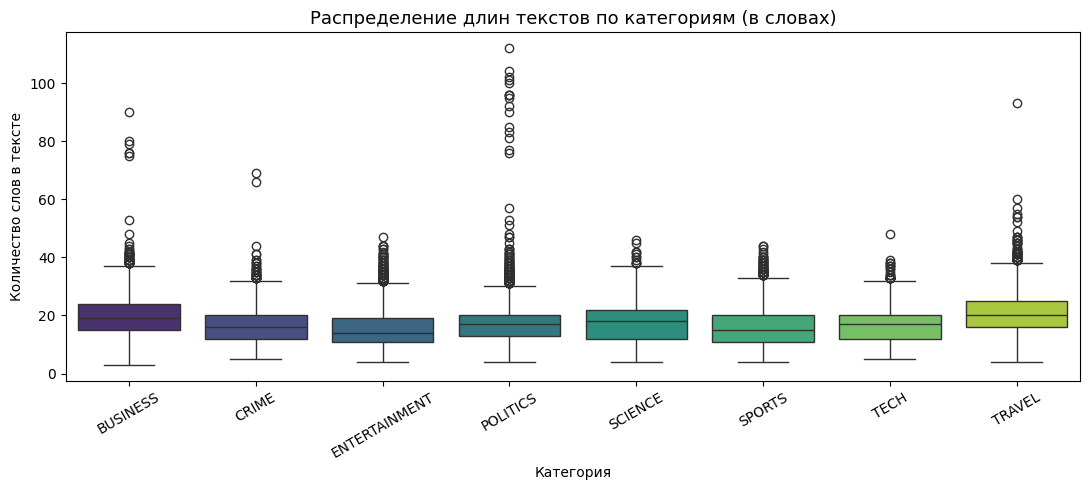

               mean   50%  min    max
category                             
BUSINESS       19.2  19.0  3.0   90.0
CRIME          16.2  16.0  5.0   69.0
ENTERTAINMENT  15.4  14.0  4.0   47.0
POLITICS       17.2  17.0  4.0  112.0
SCIENCE        17.3  18.0  4.0   46.0
SPORTS         16.0  15.0  4.0   44.0
TECH           16.7  17.0  5.0   48.0
TRAVEL         20.5  20.0  4.0   93.0


In [27]:
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x='category', y='word_count', palette='viridis')
plt.title('Распределение длин текстов по категориям (в словах)', fontsize=13)
plt.xlabel('Категория')
plt.ylabel('Количество слов в тексте')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(df.groupby('category')['word_count'].describe()[['mean', '50%', 'min', 'max']].round(1))

В среднем тексты содержат от 15 до 21 слова, что говорит о сравнительно компактной форме представления информации после предобработки.

Наибольшая средняя длина наблюдается в категориях TRAVEL (около 20.5 слов) и BUSINESS (около 19.2 слов), что может быть связано с более описательным характером текстов в данных тематиках. В то же время категории ENTERTAINMENT, SPORTS и CRIME характеризуются меньшей длиной текстов (в среднем 15-16 слов), что может отражать более краткий и событийный стиль изложения.

Медианные значения во всех категориях близки к средним, что указывает на отсутствие сильной асимметрии распределений. При этом минимальные значения (3-5 слов) свидетельствуют о наличии коротких текстов, а максимальные значения (до 112 слов в категории POLITICS) о присутствии более развернутых описаний.

В целом различия между категориями по длине текстов не являются критическими, что позволяет считать выборку достаточно однородной с точки зрения данного признака.

**Топ-20 самых часто встречающихся слов:**

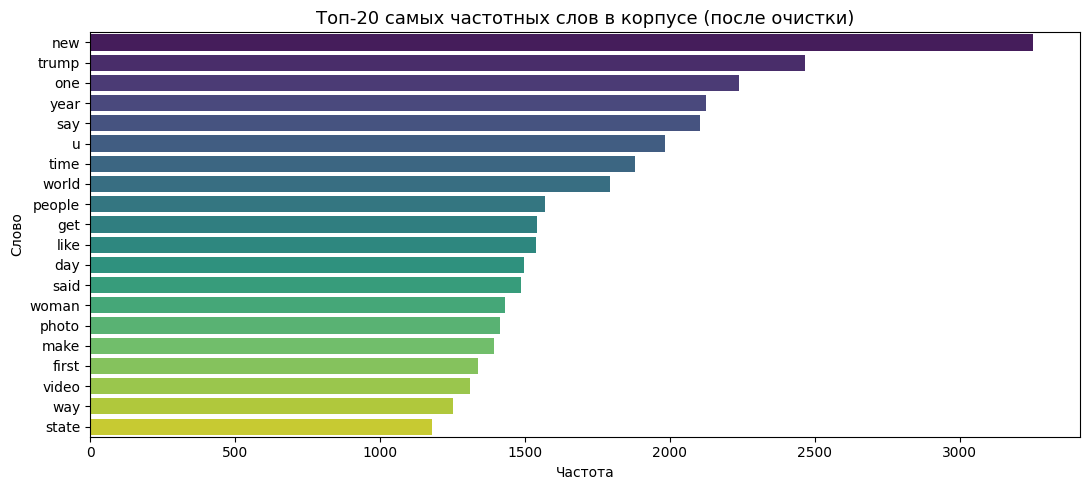

In [28]:
all_words = ' '.join(df['text']).split()
word_freq = Counter(all_words)
top_words = word_freq.most_common(20)

words, counts = zip(*top_words)

plt.figure(figsize=(11, 5))
sns.barplot(x=list(counts), y=list(words), palette='viridis')
plt.title('Топ-20 самых частотных слов в корпусе (после очистки)', fontsize=13)
plt.xlabel('Частота')
plt.ylabel('Слово')
plt.tight_layout()
plt.show()

В топ-20 входят преимущественно содержательные существительные и глаголы общего назначения - слова, которые могут встречаться в новостях любой тематики (`new`, `one`, `year`, `say`, `people` и т.п.). Это косвенно подтверждает корректность выполненной предобработки: служебная лексика успешно отфильтрована, а наиболее часто встречающиеся слова отражают универсальный новостной контекст.

Следует отметить, что слова общего назначения сами по себе слабо разделяют классы. Содержательное разделение будет обеспечиваться за счет редкой и специфической для каждой категории лексики. Это исследуем в следующих пунктах.

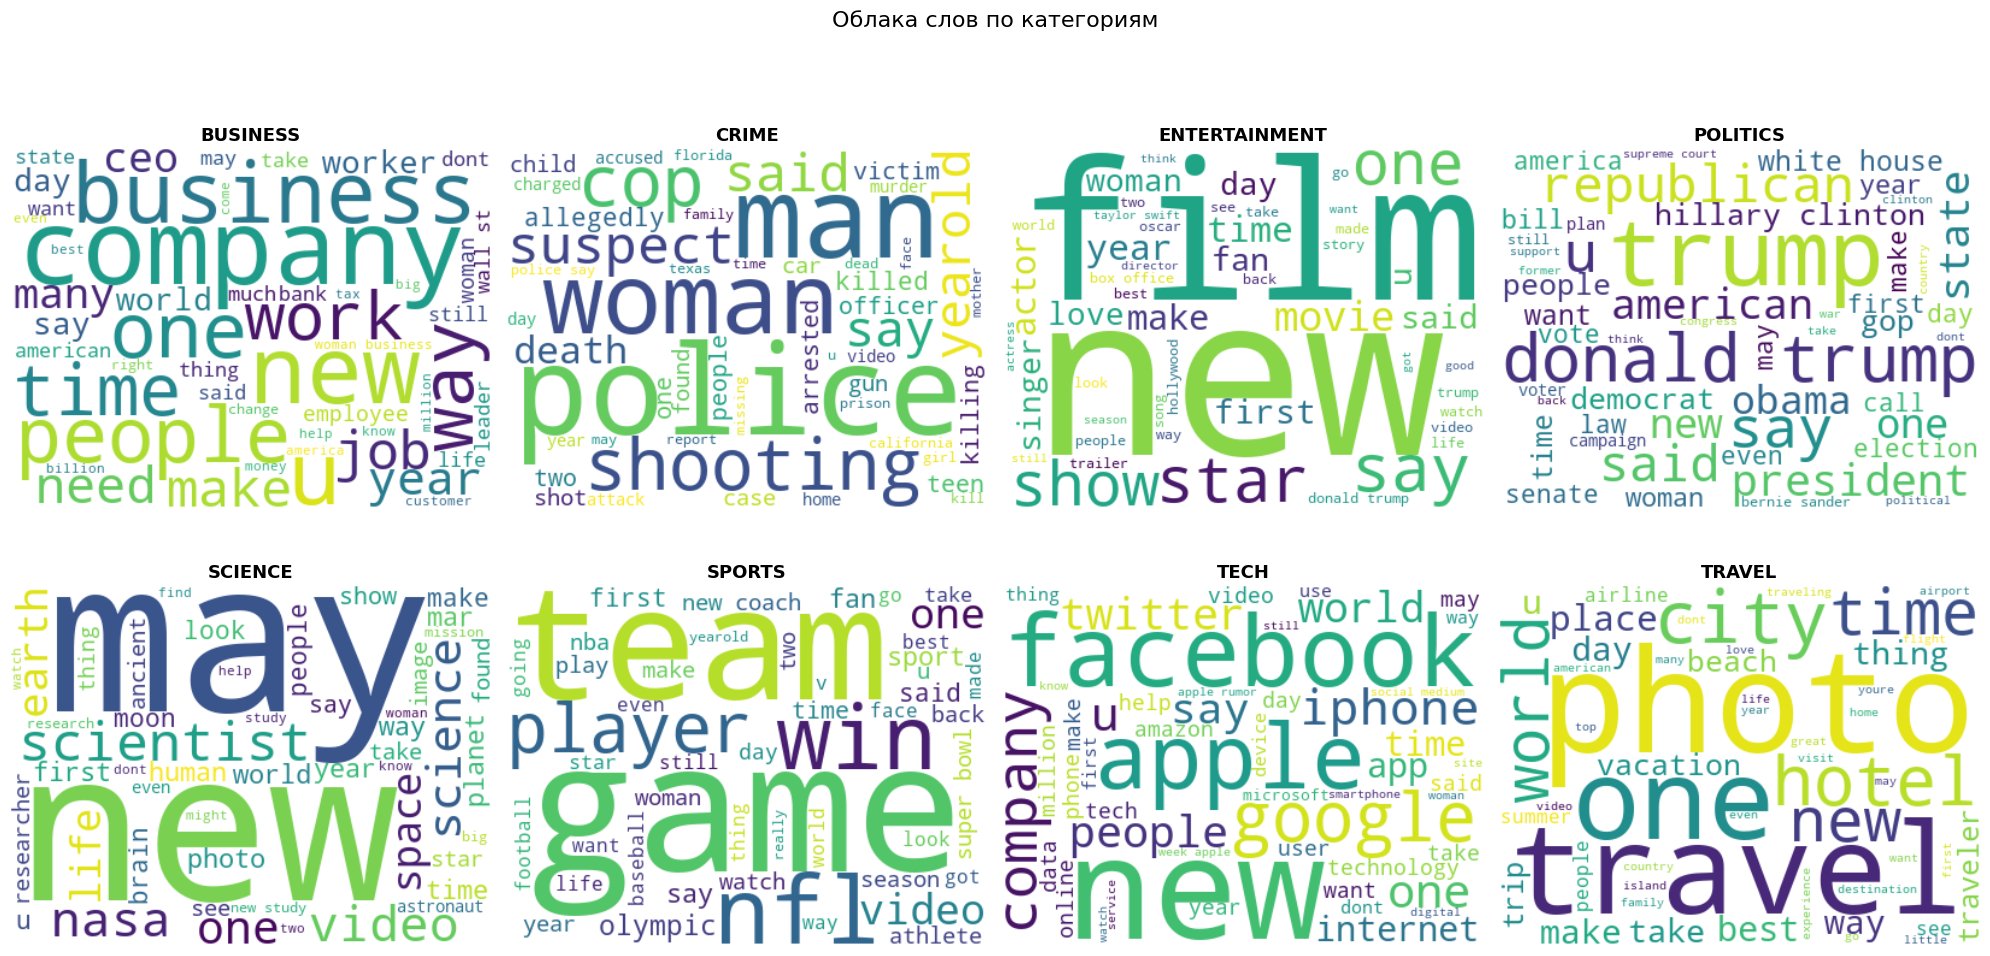

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, cat in enumerate(sorted(df['category'].unique())):
    cat_text = ' '.join(df[df['category'] == cat]['text'])
    wc = WordCloud(width=400, height=300, background_color='white',
                   max_words=50, colormap='viridis').generate(cat_text)
    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(cat, fontsize=13, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Облака слов по категориям', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Топ-15 характерных слов по каждому классу:**

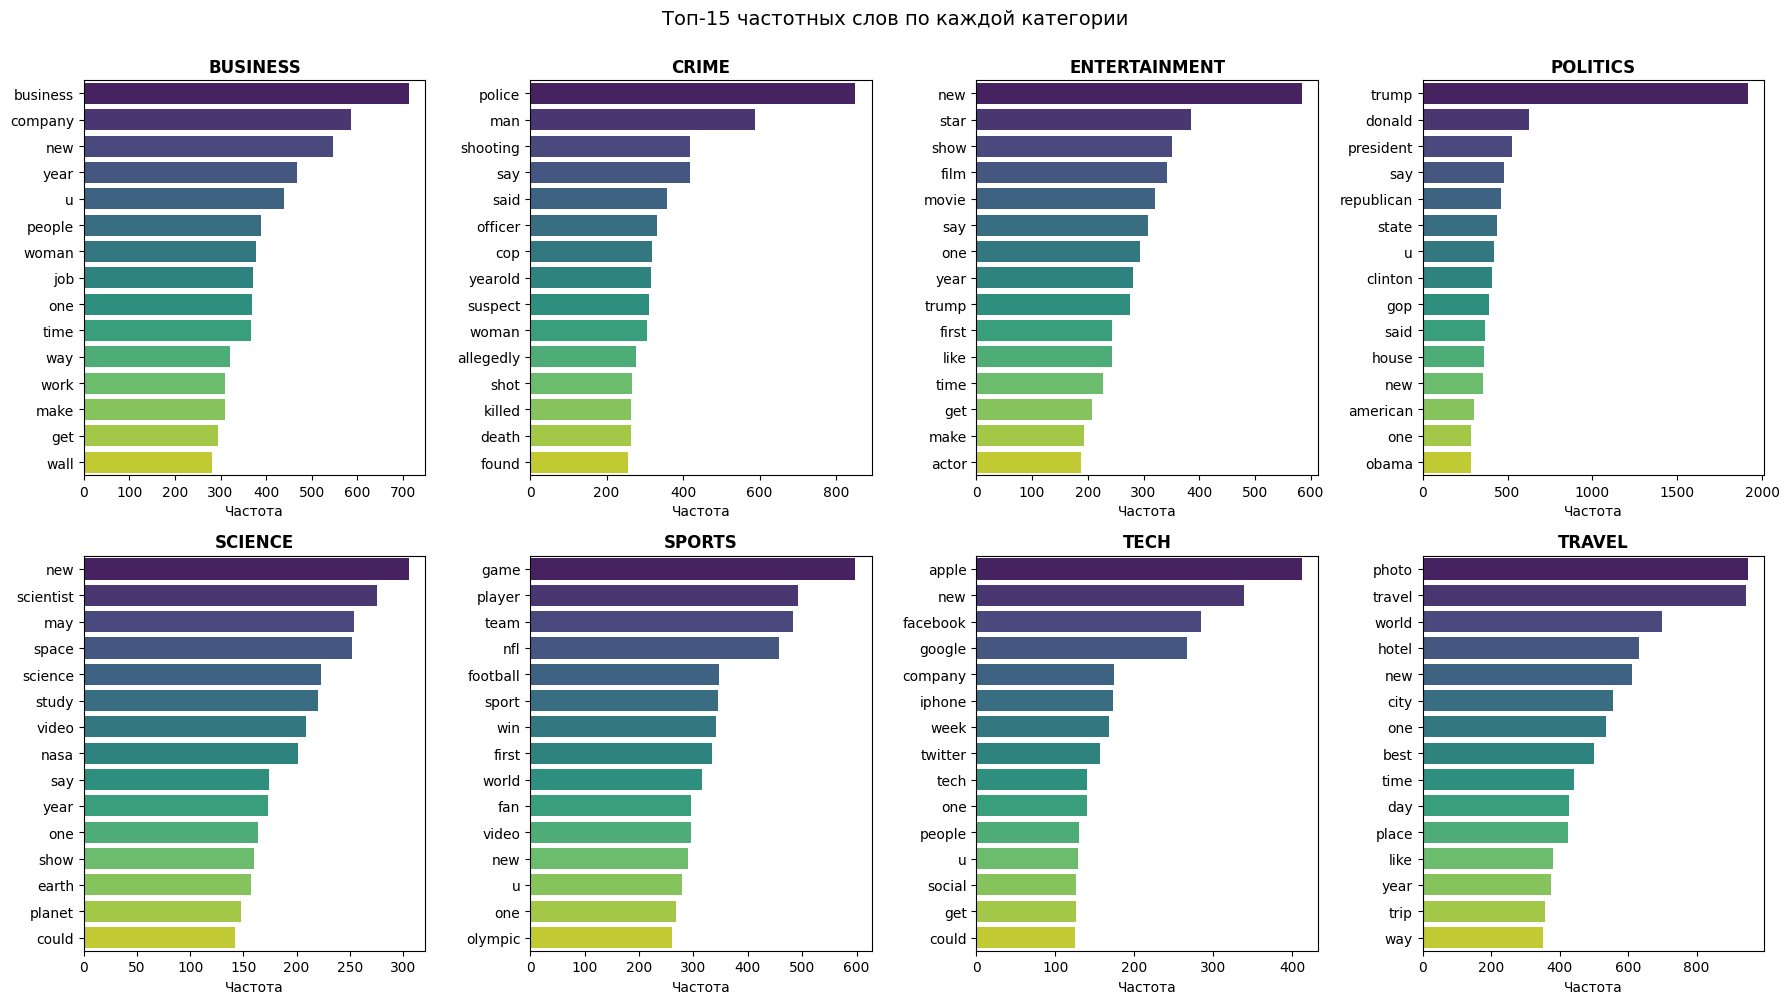

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for idx, cat in enumerate(sorted(df['category'].unique())):
    cat_words = ' '.join(df[df['category'] == cat]['text']).split()
    top = Counter(cat_words).most_common(15)
    words, counts = zip(*top)

    sns.barplot(x=list(counts), y=list(words), ax=axes[idx], palette='viridis')
    axes[idx].set_title(cat, fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Частота')
    axes[idx].set_ylabel('')

plt.suptitle('Топ-15 частотных слов по каждой категории', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

Представленный анализ наглядно демонстрирует семантическую различимость отобранных классов. Для каждой категории характерен собственный набор ключевой лексики:
- **BUSINESS** - лексика финансовой и корпоративной сферы (`company`, `business`, `job`);
- **CRIME** - лексика правоохранительной и криминальной тематики (`police`, `killed`, `shooting`, `cop`);
- **ENTERTAINMENT** - имена и термины индустрии развлечений (`show`, `movie`, `star`);
- **POLITICS** - политическая терминология (`trump`, `president`, `republican`, `obama`);
- **SCIENCE** - научная лексика (`scientist`, `space`, `study`, `nasa`);
- **SPORTS** - спортивная терминология (`game`, `team`, `player`, `football`);
- **TECH** - технологическая лексика (`apple`, `google`, `facebook`, `iphone`);
- **TRAVEL** - лексика туризма (`travel`, `hotel`, `photo`, `world`).

Наличие выраженных лексических маркеров для каждой категории подтверждает корректность постановки задачи и обосновывает применимость методов, основанных на частотном векторном представлении (TF-IDF).

**Пересечение словарей между классами:**

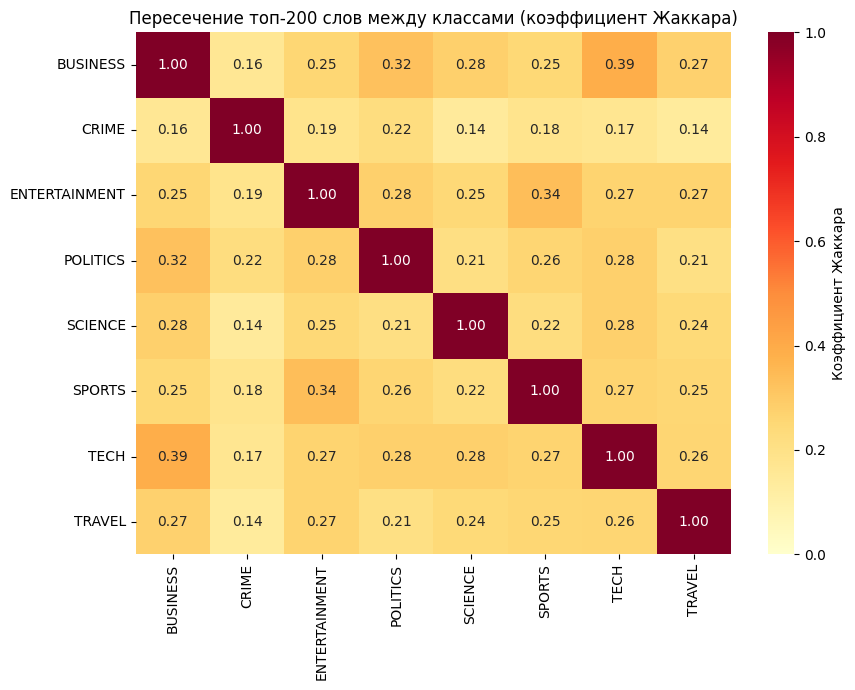

In [31]:
TOP_N = 200

class_vocabs = {}
for cat in sorted(df['category'].unique()):
    cat_words = ' '.join(df[df['category'] == cat]['text']).split()
    class_vocabs[cat] = set([w for w, _ in Counter(cat_words).most_common(TOP_N)])

cats = list(class_vocabs.keys())
n = len(cats)
jaccard = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        a, b = class_vocabs[cats[i]], class_vocabs[cats[j]]
        jaccard[i, j] = len(a & b) / len(a | b)

plt.figure(figsize=(9, 7))
sns.heatmap(jaccard, annot=True, fmt='.2f', xticklabels=cats, yticklabels=cats,
            cmap='YlOrRd', vmin=0, vmax=1, cbar_kws={'label': 'Коэффициент Жаккара'})
plt.title(f'Пересечение топ-{TOP_N} слов между классами (коэффициент Жаккара)', fontsize=12)
plt.tight_layout()
plt.show()

Для количественной оценки лексической близости классов построена матрица коэффициентов Жаккара между топ-200 словами каждой категории. Коэффициент Жаккара определяется как отношение мощности пересечения двух множеств к мощности их объединения и принимает значения от 0 (полная различность) до 1 (полное совпадение).

**Главные наблюдения:**
- значения по главной диагонали равны 1.0 (пересечение множества с самим собой);
- наиболее высокое пересечение имеют пары **BUSINESS-POLITICS**,  **BUSINESS-TECH** и **SPORTS-ENTERTAINMENT** отражая реальную содержательную близость этих рубрик (экономическая политика, технологические корпорации, спорт как развлечение);
- наиболее обособленными являются классы **SCIENCE** и **CRIME**, имеющие минимальное пересечение с остальными категориями, что позволяет прогнозировать их высокое качество распознавания.

Полученные результаты формируют **обоснованные ожидания относительно будущей модели**: наибольшие сложности ожидаются при разделении семантически близких пар (SPORTS/ENTERTAINMENT, BUSINESS/POLITICS/TECH), тогда как SCIENCE и CRIME должны классифицироваться с высоким качеством. Эти ожидания будут проверены при анализе результатов моделей.

#### **Выводы по разведочному анализу**

По результатам проведенного анализа можно сформулировать следующие содержательные выводы:

1. **Распределение целевой переменной** после балансировки является умеренно неравномерным (соотношение 2.5:1), что приемлемо для задач многоклассовой классификации и не требует дополнительных мер по балансировке.

2. **Распределение длин текстов** правосторонне асимметрично и не является нормальным. Существенных структурных различий между классами по длине текста не выявлено, что исключает риск построения модели на техническом признаке вместо содержательного.

3. **Частотный анализ** подтверждает корректность выполненной нормализации: служебная лексика устранена, частотные слова отражают содержательный новостной контекст.

4. **Анализ характерных слов по классам** демонстрирует выраженную семантическую различимость большинства категорий, что обосновывает применимость методов TF-IDF и линейных классификаторов.

5. **Анализ лексического пересечения** выявил потенциальные «зоны смешивания», что формирует обоснованные гипотезы о будущих ошибках классификации.



На основании результатов EDA принимаются следующие решения:
- **дополнительная балансировка не требуется** - остаточный дисбаланс находится в допустимых пределах;
- **удаление выбросов по длине не требуется** - аномалии отсутствуют, экстремальные значения содержательны;
- **дополнительная очистка признаков не требуется** - нормализация выполнена корректно;
- **использование TF-IDF в качестве метода векторизации обосновано** выявленным наличием характерной лексики у каждого класса.

Служебные столбцы `char_length` и `word_count`, созданные для целей разведочного анализа, удалим из рабочего датафрейма.

In [32]:
df = df.drop(columns=['char_length', 'word_count'])

## 4. TF-IDF

Для преобразования текстов в числовое представление используется метод **TF-IDF** (Term Frequency - Inverse Document Frequency), который присваивает каждому слову вес, учитывающий его частоту в конкретном документе и редкость в корпусе в целом. Вес слова в TF-IDF тем выше, чем больше его частота в конкретном документе и чем меньше его распространённость в корпусе документов.

Параметры векторизации:
- **max_features=10000** - ограничиваем словарь 10 000 наиболее значимыми признаками, что одновременно служит отбором признаков;
- **ngram_range=(1,2)** - учитываем не только отдельные слова (униграммы), но и пары слов (биграммы), что позволяет уловить устойчивые словосочетания;
- **min_df=5** - исключаем слова, встречающиеся менее чем в 5 документах, для удаления редких и нерелевантных терминов.

Данные разделим на обучающую (80%) и тестовую (20%) выборки со стратификацией по целевой переменной. Векторизатор обучается только на обучающей выборке, тестовая преобразуется без повторного обучения во избежание утечки данных.

In [33]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1,2), min_df=5, stop_words ='english')

In [34]:
X = df['text']
y = df['category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print('Train:', X_train_tfidf.shape)
print('Test:', X_test_tfidf.shape)

Train: (25123, 10000)
Test: (6281, 10000)


## 5. Методы обучения без учителя (кластеризация, PCA)

На данном этапе исследуем внутреннюю структуру данных без использования меток классов. Цель - проверить, образуют ли тексты естественные группировки, соответствующие тематическим категориям, и насколько классы разделимы в пространстве TF-IDF признаков.

Этап включает три шага:
1. **Снижение размерности через PCA** - сжимаем TF-IDF матрицу (10 000 признаков) до 100 главных компонент для ускорения последующих вычислений.
2. **Кластеризация** - применяем K-Means и агломеративную кластеризацию, оцениваем качество через силуэтный коэффициент.
3. **Визуализация через PCA 3D** - проецируем данные в трёхмерное пространство первых трёх главных компонент и сравниваем расположение точек по настоящим меткам и по найденным кластерам.

Сжимаем TF-IDF матрицу до 100 главных компонент, чтобы сохранить основную долю дисперсии данных при значительном сокращении размерности (с 10 000 до 100 признаков). Полученное представление используется в качестве входных данных для алгоритмов кластеризации, которые работают существенно быстрее в пространстве меньшей размерности.

In [35]:
pca = PCA(n_components=100, random_state=0)
X_train_pca = pca.fit_transform(X_train_tfidf.toarray())

explained = np.sum(pca.explained_variance_ratio_) * 100
print(f'Объяснённая дисперсия (100 компонент): {explained:.1f}%')
print(f'Форма матрицы после PCA: {X_train_pca.shape}')

Объяснённая дисперсия (100 компонент): 10.9%
Форма матрицы после PCA: (25123, 100)


100 компонент объясняют лишь 10.9% общей дисперсии данных. Это значение может показаться низким, однако оно является типичным для разреженных текстовых представлений: в TF-IDF матрице информация распределена по тысячам слабых признаков (слов и биграмм), и ни одна ось не доминирует. Тем не менее полученное представление достаточно для задач кластеризации и визуализации, поскольку PCA сохраняет наиболее информативные направления вариации данных.

Для проверки наличия естественных групп в данных применим два алгоритма кластеризации с числом кластеров, равным числу целевых классов (8):

- **K-Means** - разбивает данные на кластеры путем минимизации суммы квадратов расстояний от каждой точки до центра (центроида) ее кластера. Алгоритм итеративно пересчитывает центроиды и переназначает точки до сходимости.
- **Агломеративная (иерархическая) кластеризация** - последовательно объединяет ближайшие пары кластеров, начиная от отдельных точек и заканчивая заданным числом групп.

Качество кластеризации оценим с помощью **силуэтного коэффициента**, который измеряет, насколько каждый объект похож на свой кластер по сравнению с ближайшим соседним кластером. Значения близкие к 1 означают плотные и хорошо разделённые кластеры, около 0 - перекрывающиеся кластеры.

In [36]:
n_clusters = 8

kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
kmeans_labels = kmeans.fit_predict(X_train_pca)

sil_kmeans = silhouette_score(X_train_pca, kmeans_labels, sample_size=3000, random_state=0)
print(f'K-Means: силуэтный коэффициент = {sil_kmeans:.4f}')

  File "C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

K-Means: силуэтный коэффициент = 0.0719


In [37]:
agglo = AgglomerativeClustering(n_clusters=n_clusters)
agglo_labels = agglo.fit_predict(X_train_pca)

sil_agglo = silhouette_score(X_train_pca, agglo_labels, sample_size=3000, random_state=0)
print(f'Агломеративная кластеризация: силуэтный коэффициент = {sil_agglo:.4f}')

Агломеративная кластеризация: силуэтный коэффициент = 0.0647


Оба алгоритма кластеризации показали одинаково низкие значения силуэтного коэффициента. Силуэтный коэффициент принимает значения от -1 до 1, где значения близкие к 1 означают плотные и хорошо разделенные кластеры, значения около 0 указывают на перекрывающиеся кластеры, а отрицательные значения свидетельствуют о неверном отнесении объектов к кластерам.

Полученные результаты говорят о том, что в пространстве TF-IDF признаков тексты разных тематик не образуют четко обособленных групп. Это ожидаемо для новостных текстов: категории часто используют пересекающуюся лексику (что было показано ранее при анализе коэффициентов Жаккара), а тематическая информация распределена по большому числу признаков и не может быть уловлена без использования меток классов.

Для наглядной оценки структуры данных выполнена проекция TF-IDF матрицы в трехмерное пространство первых трех главных компонент


Объясненная дисперсия (3 компоненты): 0.8%


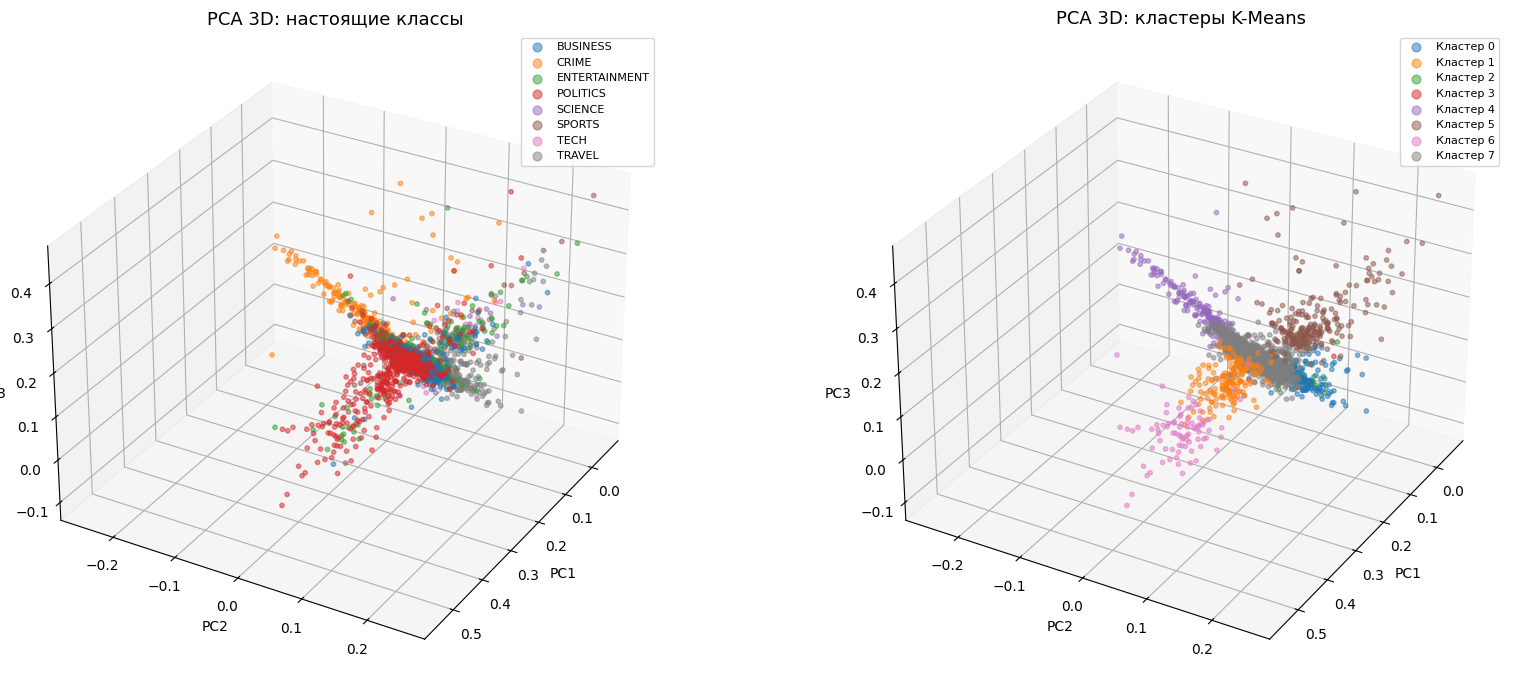

In [38]:
pca_3d = PCA(n_components=3, random_state=0)
X_3d = pca_3d.fit_transform(X_train_tfidf.toarray())
explained_3 = np.sum(pca_3d.explained_variance_ratio_) * 100
print(f'Объясненная дисперсия (3 компоненты): {explained_3:.1f}%')

sample_idx = np.random.RandomState(0).choice(len(X_3d), size=3000, replace=False)
X_sample = X_3d[sample_idx]
y_sample = y_train.iloc[sample_idx].values
kmeans_sample = kmeans_labels[sample_idx]

categories_list = sorted(np.unique(y_sample))
palette = sns.color_palette('tab10', n_colors=n_clusters)

fig = plt.figure(figsize=(18, 7))

ax1 = fig.add_subplot(121, projection='3d')
for i, cat in enumerate(categories_list):
    mask = y_sample == cat
    ax1.scatter(X_sample[mask, 0], X_sample[mask, 1], X_sample[mask, 2],
                label=cat, alpha=0.5, s=10, color=palette[i])
ax1.set_title('PCA 3D: настоящие классы', fontsize=13)
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_zlabel('PC3')
ax1.legend(markerscale=2, fontsize=8)

ax2 = fig.add_subplot(122, projection='3d')
for i in range(n_clusters):
    mask = kmeans_sample == i
    ax2.scatter(X_sample[mask, 0], X_sample[mask, 1], X_sample[mask, 2],
                label=f'Кластер {i}', alpha=0.5, s=10, color=palette[i])
ax2.set_title('PCA 3D: кластеры K-Means', fontsize=13)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_zlabel('PC3')
ax2.legend(markerscale=2, fontsize=8)
ax1.view_init(elev=30, azim=30)
ax2.view_init(elev=30, azim=30)
plt.tight_layout()
plt.show()

Низкое значение объясненной дисперсии (менее 1%) говорит о том, что информативность данных распределена по большому числу признаков и не может быть сосредоточена в нескольких осях. Это характерно для высокоразмерных разреженных текстовых представлений, таких как TF-IDF.

На левом графике точки окрашены по реальным меткам классов. Несмотря на сильное перекрытие в центральной области, можно заметить частичные тенденции к группировке: категории POLITICS и BUSINESS располагаются рядом: лексически близкие категории оказываются ближе и в пространстве признаков. Также можно заметить хорошо отделенный класс CRIME.

На правом графике те же точки окрашены по кластерам, найденным алгоритмом K-Means без использования меток. Сопоставление двух графиков показывает, что кластеризация лишь частично совпадает с реальным разделением на классы. Зона POLITICS и BUSINESS на первом графике примерно соответствует одному из кластеров на втором, однако другие категории перемешаны: например, класс CRIME оказался в том же кластере, что и ENTERTAINMENT, а значительная часть точек из различных категорий объединена алгоритмом в один крупный кластер.

#### Выводы по методам обучения без учителя

1. **Силуэтные коэффициенты** обоих алгоритмов кластеризации имеют очень низкие значения, что указывает на отсутствие четко выраженной кластерной структуры в данных.

2. **Визуализация PCA 3D** подтверждает, что классы местами довольно сильно перекрываются в пространстве TF-IDF признаков. Кластеры K-Means лишь частично совпадают с реальными категориями.

3. **Низкая объясненная дисперсия** первых компонент говорит о том, что тематическая информация распределена по большому числу слабых признаков, характерному для разреженных текстовых представлений.

Таким образом, в данной задаче необходимо использовать методы обучения с учителем для решения задачи классификации. Без использования размеченных данных алгоритмы не способны четко разделить тексты по тематическим категориям.

## 6. Обучение моделей

На данном этапе обучим 10 моделей классификации на TF-IDF представлении текстов.

**Линейные модели:**
- **Logistic Regression** - обобщение логистической регрессии на многоклассовый случай. Строит линейную разделяющую границу между классами, оптимизируя логарифмическую функцию потерь.
- **SVM (LinearSVC)** - метод опорных векторов, который ищет гиперплоскость с максимальным отступом между классами. Хорошо работает в высокоразмерных пространствах.
- **SGD Classifier** - стохастический градиентный спуск. По сути решает ту же задачу, что и SVM или логистическая регрессия, но оптимизирует функцию потерь не на всей выборке, а на случайных мини-батчах, что делает его значительно быстрее на больших данных.
- **Ridge Classifier** - линейная модель с L2-регуляризацией, которая штрафует слишком большие веса признаков и предотвращает переобучение.
- **Perceptron** - простейшая линейная модель, обновляющая веса только при ошибочной классификации. Быстрая, но менее устойчивая к шуму.

**Вероятностная модель:**
- **Naive Bayes (MultinomialNB)** - основана на теореме Байеса с допущением о независимости признаков. Несмотря на упрощенное предположение, хорошо зарекомендовала себя в задачах классификации текстов.

**Модель на основе расстояний:**
- **kNN (k ближайших соседей)** - классифицирует объект по большинству меток среди k ближайших соседей в пространстве признаков. Не строит явной модели, а запоминает обучающую выборку.

**Модели с деревьями и ансамбли:**
- **Decision Tree** - строит дерево решений, последовательно разбивая данные по наиболее информативным признакам.
- **Random Forest** - ансамбль деревьев решений, обученных на случайных подвыборках данных и признаков (метод бэггинга). Снижает дисперсию предсказаний по сравнению с одиночным деревом.
- **Gradient Boosting** - ансамбль деревьев, обучаемых последовательно: каждое следующее дерево исправляет ошибки предыдущих (метод бустинга).

Для каждой модели выполним 5-fold кросс-валидация с метрикой F1 (weighted), замер времени обучения и оценим на тестовой выборке. Все результаты соберем в единую таблицу для последующего сравнения.

In [39]:
def model_eval(model, model_name, X_train, X_test, y_train, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1_weighted')

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f' {model_name} ')
    print(f'Время обучения: {train_time:.2f} сек')
    print(f'Кросс-валидация F1 (mean +- std): {cv_scores.mean():.4f} +- {cv_scores.std():.4f}')
    print(f'Accuracy (test): {acc:.4f}')
    print(f'F1 (test): {f1:.4f}')
    print()
    print(classification_report(y_test, y_pred))
    print()

    return {
        'model': model_name,
        'train_time': train_time,
        'cv_f1_mean': cv_scores.mean(),
        'cv_f1_std': cv_scores.std(),
        'test_accuracy': acc,
        'test_f1': f1
    }

In [40]:
results = []
results.append(model_eval(LogisticRegression(max_iter=1000), 'Logistic Regression', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Logistic Regression 
Время обучения: 1.92 сек
Кросс-валидация F1 (mean +- std): 0.8027 +- 0.0069
Accuracy (test): 0.8091
F1 (test): 0.8074

               precision    recall  f1-score   support

     BUSINESS       0.73      0.80      0.76       943
        CRIME       0.81      0.84      0.83       675
ENTERTAINMENT       0.78      0.84      0.81       945
     POLITICS       0.81      0.80      0.80       979
      SCIENCE       0.86      0.65      0.75       411
       SPORTS       0.89      0.85      0.87       941
         TECH       0.82      0.58      0.68       410
       TRAVEL       0.83      0.90      0.86       977

     accuracy                           0.81      6281
    macro avg       0.82      0.78      0.79      6281
 weighted avg       0.81      0.81      0.81      6281




In [41]:
results.append(model_eval(MultinomialNB(), 'Naive Bayes', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Naive Bayes 
Время обучения: 0.22 сек
Кросс-валидация F1 (mean +- std): 0.7778 +- 0.0082
Accuracy (test): 0.7889
F1 (test): 0.7814

               precision    recall  f1-score   support

     BUSINESS       0.66      0.80      0.73       943
        CRIME       0.81      0.85      0.83       675
ENTERTAINMENT       0.81      0.81      0.81       945
     POLITICS       0.78      0.82      0.80       979
      SCIENCE       0.96      0.51      0.67       411
       SPORTS       0.88      0.86      0.87       941
         TECH       0.88      0.34      0.49       410
       TRAVEL       0.77      0.92      0.84       977

     accuracy                           0.79      6281
    macro avg       0.82      0.74      0.75      6281
 weighted avg       0.80      0.79      0.78      6281




In [42]:
results.append(model_eval(KNeighborsClassifier(), 'kNN', X_train_tfidf, X_test_tfidf, y_train, y_test))

 kNN 
Время обучения: 0.08 сек
Кросс-валидация F1 (mean +- std): 0.6904 +- 0.0051
Accuracy (test): 0.6961
F1 (test): 0.6959

               precision    recall  f1-score   support

     BUSINESS       0.58      0.71      0.64       943
        CRIME       0.69      0.73      0.71       675
ENTERTAINMENT       0.72      0.71      0.71       945
     POLITICS       0.72      0.72      0.72       979
      SCIENCE       0.67      0.58      0.62       411
       SPORTS       0.79      0.77      0.78       941
         TECH       0.65      0.50      0.56       410
       TRAVEL       0.74      0.70      0.72       977

     accuracy                           0.70      6281
    macro avg       0.69      0.67      0.68      6281
 weighted avg       0.70      0.70      0.70      6281




In [43]:
results.append(model_eval(LinearSVC(max_iter=2000), 'SVM', X_train_tfidf, X_test_tfidf, y_train, y_test))

 SVM 
Время обучения: 2.76 сек
Кросс-валидация F1 (mean +- std): 0.8007 +- 0.0066
Accuracy (test): 0.8059
F1 (test): 0.8051

               precision    recall  f1-score   support

     BUSINESS       0.75      0.77      0.76       943
        CRIME       0.81      0.83      0.82       675
ENTERTAINMENT       0.80      0.82      0.81       945
     POLITICS       0.79      0.79      0.79       979
      SCIENCE       0.78      0.70      0.74       411
       SPORTS       0.88      0.86      0.87       941
         TECH       0.76      0.65      0.70       410
       TRAVEL       0.84      0.88      0.86       977

     accuracy                           0.81      6281
    macro avg       0.80      0.79      0.79      6281
 weighted avg       0.81      0.81      0.81      6281




In [44]:
results.append(model_eval(DecisionTreeClassifier(random_state=42), 'Decision Tree', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Decision Tree 
Время обучения: 40.54 сек
Кросс-валидация F1 (mean +- std): 0.6344 +- 0.0064
Accuracy (test): 0.6365
F1 (test): 0.6360

               precision    recall  f1-score   support

     BUSINESS       0.60      0.57      0.58       943
        CRIME       0.65      0.67      0.66       675
ENTERTAINMENT       0.59      0.64      0.61       945
     POLITICS       0.67      0.69      0.68       979
      SCIENCE       0.55      0.53      0.54       411
       SPORTS       0.70      0.67      0.69       941
         TECH       0.53      0.49      0.51       410
       TRAVEL       0.69      0.70      0.69       977

     accuracy                           0.64      6281
    macro avg       0.62      0.62      0.62      6281
 weighted avg       0.64      0.64      0.64      6281




In [45]:
results.append(model_eval(RandomForestClassifier(n_estimators=100, random_state=42), 'Random Forest', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Random Forest 
Время обучения: 160.38 сек
Кросс-валидация F1 (mean +- std): 0.7216 +- 0.0088
Accuracy (test): 0.7305
F1 (test): 0.7290

               precision    recall  f1-score   support

     BUSINESS       0.70      0.69      0.69       943
        CRIME       0.70      0.81      0.75       675
ENTERTAINMENT       0.63      0.72      0.67       945
     POLITICS       0.74      0.77      0.76       979
      SCIENCE       0.76      0.60      0.67       411
       SPORTS       0.83      0.76      0.79       941
         TECH       0.79      0.49      0.60       410
       TRAVEL       0.77      0.82      0.80       977

     accuracy                           0.73      6281
    macro avg       0.74      0.71      0.72      6281
 weighted avg       0.74      0.73      0.73      6281




In [46]:
results.append(model_eval(GradientBoostingClassifier(n_estimators=100, random_state=42), 'Gradient Boosting', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Gradient Boosting 
Время обучения: 304.37 сек
Кросс-валидация F1 (mean +- std): 0.7160 +- 0.0071
Accuracy (test): 0.7123
F1 (test): 0.7182

               precision    recall  f1-score   support

     BUSINESS       0.75      0.64      0.69       943
        CRIME       0.76      0.75      0.76       675
ENTERTAINMENT       0.48      0.79      0.60       945
     POLITICS       0.79      0.73      0.76       979
      SCIENCE       0.81      0.59      0.68       411
       SPORTS       0.86      0.72      0.78       941
         TECH       0.73      0.59      0.65       410
       TRAVEL       0.79      0.76      0.77       977

     accuracy                           0.71      6281
    macro avg       0.75      0.70      0.71      6281
 weighted avg       0.74      0.71      0.72      6281




In [47]:
results.append(model_eval(SGDClassifier(random_state=42), 'SGD', X_train_tfidf, X_test_tfidf, y_train, y_test))

 SGD 
Время обучения: 0.35 сек
Кросс-валидация F1 (mean +- std): 0.8127 +- 0.0061
Accuracy (test): 0.8195
F1 (test): 0.8179

               precision    recall  f1-score   support

     BUSINESS       0.78      0.78      0.78       943
        CRIME       0.80      0.86      0.83       675
ENTERTAINMENT       0.83      0.82      0.82       945
     POLITICS       0.81      0.82      0.81       979
      SCIENCE       0.84      0.71      0.77       411
       SPORTS       0.87      0.87      0.87       941
         TECH       0.80      0.62      0.70       410
       TRAVEL       0.82      0.91      0.87       977

     accuracy                           0.82      6281
    macro avg       0.82      0.80      0.81      6281
 weighted avg       0.82      0.82      0.82      6281




In [48]:
results.append(model_eval(RidgeClassifier(), 'Ridge Classifier', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Ridge Classifier 
Время обучения: 0.66 сек
Кросс-валидация F1 (mean +- std): 0.8112 +- 0.0046
Accuracy (test): 0.8166
F1 (test): 0.8155

               precision    recall  f1-score   support

     BUSINESS       0.77      0.78      0.78       943
        CRIME       0.82      0.85      0.83       675
ENTERTAINMENT       0.81      0.83      0.82       945
     POLITICS       0.80      0.81      0.80       979
      SCIENCE       0.82      0.71      0.76       411
       SPORTS       0.89      0.87      0.88       941
         TECH       0.80      0.65      0.72       410
       TRAVEL       0.82      0.89      0.86       977

     accuracy                           0.82      6281
    macro avg       0.82      0.80      0.81      6281
 weighted avg       0.82      0.82      0.82      6281




In [49]:
results.append(model_eval(Perceptron(random_state=42), 'Perceptron', X_train_tfidf, X_test_tfidf, y_train, y_test))

 Perceptron 
Время обучения: 0.39 сек
Кросс-валидация F1 (mean +- std): 0.7482 +- 0.0069
Accuracy (test): 0.7583
F1 (test): 0.7580

               precision    recall  f1-score   support

     BUSINESS       0.70      0.69      0.70       943
        CRIME       0.78      0.77      0.78       675
ENTERTAINMENT       0.78      0.77      0.77       945
     POLITICS       0.73      0.77      0.75       979
      SCIENCE       0.69      0.67      0.68       411
       SPORTS       0.84      0.81      0.83       941
         TECH       0.63      0.60      0.62       410
       TRAVEL       0.81      0.85      0.83       977

     accuracy                           0.76      6281
    macro avg       0.75      0.74      0.74      6281
 weighted avg       0.76      0.76      0.76      6281




In [50]:
results = pd.DataFrame(results).sort_values(by='cv_f1_mean', ascending=False)
results

,model,train_time,cv_f1_mean,cv_f1_std,test_accuracy,test_f1
7,SGD,0.346626,0.812661,0.006137,0.819456,0.817869
8,Ridge Classifier,0.662222,0.811158,0.004584,0.816590,0.815533
0,Logistic Regression,1.917264,0.802693,0.006930,0.809107,0.807441
3,SVM,2.755524,0.800652,0.006589,0.805923,0.805133
1,Naive Bayes,0.221385,0.777791,0.008213,0.788887,0.781390
9,Perceptron,0.393199,0.748187,0.006922,0.758319,0.758041
5,Random Forest,160.381962,0.721626,0.008794,0.730457,0.729042
6,Gradient Boosting,304.368144,0.716014,0.007068,0.712307,0.718154
2,kNN,0.076436,0.690371,0.005085,0.696068,0.695899
4,Decision Tree,40.543961,0.634373,0.006351,0.636523,0.635971


#### Анализ результатов обучения

По результатам обучения 10 моделей можно выделить несколько закономерностей:

**Лидеры - линейные модели.** Лучшие результаты показали SGD (F1 = 0.818), Ridge Classifier (F1 = 0.816) и Logistic Regression (F1 = 0.807). Это закономерно для задач классификации текстов с TF-IDF представлением: высокоразмерное разреженное пространство признаков хорошо разделяется линейными границами.

**Древесные модели уступают линейным.** Random Forest (F1 = 0.729), Gradient Boosting (F1 = 0.718) и особенно Decision Tree (F1 = 0.636) показали значительно более низкое качество. Это связано с тем, что деревья решений плохо работают с разреженными высокоразмерными данными: при 10 000 TF-IDF признаков им приходится делать огромное количество разбиений, что приводит к неэффективному обучению. Кроме того, Gradient Boosting потребовал наибольшего времени обучения (около 300 секунд).

**kNN - худший среди нетривиальных моделей** (F1 = 0.696). В высокоразмерных пространствах расстояния между точками становятся менее информативными (так называемое «проклятие размерности»), что снижает эффективность метода ближайших соседей.

**Кросс-валидация и тест согласованы.** Значения F1 на кросс-валидации и на тестовой выборке близки для всех моделей, поэтому значительного переобучения нет.

Для дальнейшей настройки гиперпараметров и построения ансамблей будут использованы три лучшие модели: **SGD, Ridge Classifier и Logistic Regression**. Отбираем их по F1 на кросс-валидации (`cv_f1_mean`), а не по тестовой выборке, чтобы тест не участвовал в выборе модели.

## 7. Настройка гиперпараметров

На предыдущем этапе были определены три лучшие модели: SGD, Ridge Classifier и Logistic Regression. Для повышения качества классификации выполним подбор оптимальных гиперпараметров с помощью **GridSearchCV** — метода полного перебора заданных комбинаций параметров с оценкой каждой комбинации через 5-fold кросс-валидацию.

Для каждой модели определена сетка параметров, охватывающая основные настройки, влияющие на качество:
- **SGD** - функция потерь (hinge, log_loss, modified_huber), сила регуляризации (alpha) и тип штрафа (L1, L2, Elastic Net).
- **Ridge Classifier** - сила регуляризации (alpha), определяющая баланс между точностью на обучающей выборке и сложностью модели.
- **Logistic Regression** - сила регуляризации (C), тип штрафа (L1, L2) и алгоритм оптимизации.

In [51]:
sgd_params = {
    'loss': ['hinge', 'log_loss', 'modified_huber'],
    'alpha': [1e-5, 1e-4, 1e-3],
    'penalty': ['l1', 'l2', 'elasticnet']
}

sgd_grid = GridSearchCV(
    SGDClassifier(random_state=42),
    sgd_params, cv=5, scoring='f1_weighted', n_jobs=-1
)
sgd_grid.fit(X_train_tfidf, y_train)

print('SGD')
print(f'Лучшие параметры: {sgd_grid.best_params_}')
print(f'Лучший F1 (CV): {sgd_grid.best_score_:.4f}')
print()

SGD
Лучшие параметры: {'alpha': 0.0001, 'loss': 'hinge', 'penalty': 'l2'}
Лучший F1 (CV): 0.8127



In [52]:
ridge_params = {
    'alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
}

ridge_grid = GridSearchCV(
    RidgeClassifier(),
    ridge_params, cv=5, scoring='f1_weighted', n_jobs=-1
)
ridge_grid.fit(X_train_tfidf, y_train)

print('Ridge Classifier')
print(f'Лучшие параметры: {ridge_grid.best_params_}')
print(f'Лучший F1 (CV): {ridge_grid.best_score_:.4f}')
print()

Ridge Classifier
Лучшие параметры: {'alpha': 1.0}
Лучший F1 (CV): 0.8112



In [53]:
lr_params = {
    'C': [0.1, 0.5, 1.0, 5.0, 10.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_params, cv=5, scoring='f1_weighted', n_jobs=-1
)
lr_grid.fit(X_train_tfidf, y_train)

print('Logistic Regression')
print(f'Лучшие параметры: {lr_grid.best_params_}')
print(f'Лучший F1 (CV): {lr_grid.best_score_:.4f}')

Logistic Regression
Лучшие параметры: {'C': 5.0, 'penalty': 'l2', 'solver': 'liblinear'}
Лучший F1 (CV): 0.8094


In [54]:
print('Результаты на тестовой выборке после настройки')

for name, grid in [('SGD', sgd_grid), ('Ridge Classifier', ridge_grid), ('Logistic Regression', lr_grid)]:
    y_pred = grid.best_estimator_.predict(X_test_tfidf)
    f1 = f1_score(y_test, y_pred, average='weighted')
    acc = accuracy_score(y_test, y_pred)
    print(f'{name}: Accuracy = {acc:.4f}, F1 = {f1:.4f}')
    print(f'Параметры: {grid.best_params_}')

Результаты на тестовой выборке после настройки
SGD: Accuracy = 0.8195, F1 = 0.8179
Параметры: {'alpha': 0.0001, 'loss': 'hinge', 'penalty': 'l2'}
Ridge Classifier: Accuracy = 0.8166, F1 = 0.8155
Параметры: {'alpha': 1.0}
Logistic Regression: Accuracy = 0.8131, F1 = 0.8120
Параметры: {'C': 5.0, 'penalty': 'l2', 'solver': 'liblinear'}


#### Результаты настройки гиперпараметров

Подбор гиперпараметров позволил уточнить конфигурацию лучших моделей. Сравнение результатов до и после настройки:

| Модель              | F1 до настройки | F1 после настройки | Лучшие параметры |
|---------------------|----------------|--------------------|------------------|
| SGD                 | 0.8179         | 0.8179             | loss=hinge, alpha=0.0001, penalty=L2 |
| Ridge Classifier    | 0.8155         | 0.8155             | alpha=1.0        |
| Logistic Regression | 0.8074         | 0.8120             | C=5.0, penalty=L2, solver=liblinear |

Результаты SGD и Ridge Classifier остались на прежнем уровне, что свидетельствует о том, что параметры по умолчанию уже были близки к оптимальным. Logistic Regression показала незначительное улучшение (+0.005 F1) при увеличении параметра C до 5.0, что соответствует ослаблению регуляризации и позволяет модели точнее подстроиться под данные.

Все три модели используют L2-регуляризацию в качестве оптимального типа штрафа. Это ожидаемо для TF-IDF представлений: L2-штраф равномерно уменьшает веса всех признаков, что предпочтительнее L1-отбора в ситуации, когда информативность распределена по большому числу слов.

Настроенные модели будут использованы в качестве базовых классификаторов для построения ансамблей на следующем этапе.

## 8. Эксперимент с class_weight='balanced'


Помимо undersampling, примененного на этапе подготовки данных, существует альтернативный подход к борьбе с дисбалансом классов - использование параметра `class_weight='balanced'`. При его включении модель автоматически назначает классам с меньшим числом примеров больший вес в функции потерь, что компенсирует их недостаточную представленность.

Проверим, дает ли этот параметр дополнительное улучшение на уже частично сбалансированных данных (после undersampling классы SCIENCE и TECH по-прежнему содержат примерно в 2 раза меньше записей, чем остальные).

In [55]:
cw_results = []

sgd_base = SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42)
sgd_base.fit(X_train_tfidf, y_train)
f1_base_sgd = f1_score(y_test, sgd_base.predict(X_test_tfidf), average='weighted')

sgd_bal = SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42, class_weight='balanced')
sgd_bal.fit(X_train_tfidf, y_train)
f1_bal_sgd = f1_score(y_test, sgd_bal.predict(X_test_tfidf), average='weighted')

cw_results.append({'Модель': 'SGD', 'F1 без class_weight': round(f1_base_sgd, 4), 'F1 с class_weight': round(f1_bal_sgd, 4)})

In [56]:
lr_base = LogisticRegression(C=5.0, penalty='l2', solver='liblinear', max_iter=1000, random_state=42)
lr_base.fit(X_train_tfidf, y_train)
f1_base_lr = f1_score(y_test, lr_base.predict(X_test_tfidf), average='weighted')

lr_bal = LogisticRegression(C=5.0, penalty='l2', solver='liblinear', max_iter=1000, random_state=42, class_weight='balanced')
lr_bal.fit(X_train_tfidf, y_train)
f1_bal_lr = f1_score(y_test, lr_bal.predict(X_test_tfidf), average='weighted')

cw_results.append({'Модель': 'Logistic Regression', 'F1 без class_weight': round(f1_base_lr, 4), 'F1 с class_weight': round(f1_bal_lr, 4)})

In [57]:
svm_base = LinearSVC(max_iter=2000, random_state=42)
svm_base.fit(X_train_tfidf, y_train)
f1_base_svm = f1_score(y_test, svm_base.predict(X_test_tfidf), average='weighted')

svm_bal = LinearSVC(max_iter=2000, random_state=42, class_weight='balanced')
svm_bal.fit(X_train_tfidf, y_train)
f1_bal_svm = f1_score(y_test, svm_bal.predict(X_test_tfidf), average='weighted')

cw_results.append({'Модель': 'SVM', 'F1 без class_weight': round(f1_base_svm, 4), 'F1 с class_weight': round(f1_bal_svm, 4)})

In [58]:
cw_df = pd.DataFrame(cw_results)
cw_df['Разница'] = (cw_df['F1 с class_weight'] - cw_df['F1 без class_weight']).round(4)
cw_df

,Модель,F1 без class_weight,F1 с class_weight,Разница
0,SGD,0.8179,0.8199,0.0020
1,Logistic Regression,0.8120,0.8150,0.0030
2,SVM,0.8051,0.8063,0.0012


## 9. Ансамблирование (Voting и Stacking)

На данном этапе объединим лучшие модели в ансамбли для проверки гипотезы о том, что комбинация нескольких классификаторов может превзойти каждый из них по отдельности.

Применим два подхода:
- **VotingClassifier (голосование)** - итоговый класс определяется большинством голосов базовых моделей. Каждая модель делает своё предсказание, и выбирается класс, за который проголосовало наибольшее число моделей (hard voting).
- **StackingClassifier (стекинг)** - предсказания базовых моделей используются как входные признаки для мета-модели (модель второго уровня, которая обучается комбинировать предсказания базовых классификаторов; в нашем случае Logistic Regression), которая обучается находить оптимальную комбинацию базовых предсказаний. Стекинг потенциально мощнее голосования, так как мета-модель способна учитывать, в каких ситуациях какая базовая модель точнее.

В качестве базовых классификаторов используем три лучшие модели с оптимальными гиперпараметрами, найденными на предыдущем этапе. Для SGD и Logistic Regression дополнительно включим параметр `class_weight='balanced'`, который показал положительный эффект в эксперименте по борьбе с дисбалансом классов. Для Ridge Classifier данный параметр недоступен.

In [59]:
estimators = [
    ('sgd', SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42, class_weight='balanced')),
    ('ridge', RidgeClassifier(alpha=1.0)),
    ('lr', LogisticRegression(C=5.0, penalty='l2', solver='liblinear', max_iter=1000, random_state=42, class_weight='balanced'))
]

voting = VotingClassifier(estimators=estimators, voting='hard')
voting.fit(X_train_tfidf, y_train)

y_pred_vot = voting.predict(X_test_tfidf)
f1_vot = f1_score(y_test, y_pred_vot, average='weighted')
acc_vot = accuracy_score(y_test, y_pred_vot)

print('Voting (hard)')
print(f'Accuracy: {acc_vot:.4f}, F1: {f1_vot:.4f}')
print()

stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5
)
stacking.fit(X_train_tfidf, y_train)

y_pred_stack = stacking.predict(X_test_tfidf)
f1_stack = f1_score(y_test, y_pred_stack, average='weighted')
acc_stack = accuracy_score(y_test, y_pred_stack)

print('Stacking')
print(f'Accuracy: {acc_stack:.4f}, F1: {f1_stack:.4f}')

Voting (hard)
Accuracy: 0.8207, F1: 0.8202

Stacking
Accuracy: 0.8209, F1: 0.8202


In [60]:
def acc_f1(model):
    pred = model.predict(X_test_tfidf)
    return accuracy_score(y_test, pred), f1_score(y_test, pred, average='weighted')

rows = []
for name, model in [('SGD (настроенный)', sgd_grid.best_estimator_),
                    ('SGD + class_weight', sgd_bal),
                    ('Ridge Classifier (настроенный)', ridge_grid.best_estimator_),
                    ('Logistic Regression (настроенная)', lr_grid.best_estimator_),
                    ('LR + class_weight', lr_bal)]:
    acc, f1 = acc_f1(model)
    rows.append({'Модель': name, 'Accuracy': acc, 'F1': f1})

comparison = pd.DataFrame(rows + [
    {'Модель': 'Voting (hard)', 'Accuracy': acc_vot, 'F1': f1_vot},
    {'Модель': 'Stacking', 'Accuracy': acc_stack, 'F1': f1_stack},
]).sort_values(by='F1', ascending=False)

comparison

,Модель,Accuracy,F1
5,Voting (hard),0.820729,0.820204
6,Stacking,0.820888,0.820177
1,SGD + class_weight,0.820092,0.819911
0,SGD (настроенный),0.819456,0.817869
2,Ridge Classifier (настроенный),0.816590,0.815533
4,LR + class_weight,0.815316,0.814997
3,Logistic Regression (настроенная),0.813087,0.811963


Лучший результат показал **Voting (hard)** с F1 = 0.8202, но преимущество минимальное: настроенную SGD он опережает на +0.002, а SGD с `class_weight='balanced'` (F1 = 0.8199) почти не превосходит. Включение параметра `class_weight='balanced'` в базовые модели положительно сказалось на качестве голосования: модели стали лучше распознавать миноритарные классы (SCIENCE, TECH), что увеличило разнообразие предсказаний и повысило эффективность голосования.

Stacking показал практически такой же результат (F1 = 0.8202, разница с Voting только в пятом знаке), а по accuracy даже чуть выше (0.8209 против 0.8207). То есть в этой задаче оба способа ансамблирования равноценны.

Таким образом, ансамбли дали лучший результат, но выигрыш по сравнению с одиночной SGD с учетом дисбаланса классов очень мал. Скромный прирост от ансамблирования объясняется однородностью базовых моделей: все три классификатора являются линейными и ошибаются в схожих ситуациях, что ограничивает потенциал их комбинирования. Более существенный прирост мог бы быть достигнут за счет включения в ансамбль моделей принципиально иной природы (например, вероятностных или древесных), однако в данной задаче такие модели показали значительно более низкое индивидуальное качество, что делает их включение нецелесообразным.

## 10. Дополнительные эксперименты (PCA, LSA)

### 10.1 PCA

Ранее модели обучались на полной TF-IDF матрице (10 000 признаков). На данном этапе проверим, как влияет предварительное снижение размерности через PCA на качество классификации.

Эксперимент заключается в следующем: обучим лучшую модель (Voting) и лучшую одиночную модель (SGD) на PCA-представлении данных с различным числом компонент (50, 100, 200, 500) и сравним результаты с обучением на полном TF-IDF. Это позволит оценить, можно ли сократить размерность без существенной потери качества, а также выявить, какой объём информации действительно необходим для решения задачи.

In [61]:
n_components_list = [50, 100, 200, 500]
pca_results = []

X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

for n_comp in n_components_list:
    pca_exp = PCA(n_components=n_comp, random_state=0)
    X_train_pca_exp = pca_exp.fit_transform(X_train_dense)
    X_test_pca_exp = pca_exp.transform(X_test_dense)

    explained = np.sum(pca_exp.explained_variance_ratio_) * 100

    sgd_model = SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42, class_weight='balanced')
    sgd_model.fit(X_train_pca_exp, y_train)
    f1_sgd = f1_score(y_test, sgd_model.predict(X_test_pca_exp), average='weighted')

    estimators_pca = [
        ('sgd', SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42, class_weight='balanced')),
        ('ridge', RidgeClassifier(alpha=1.0)),
        ('lr', LogisticRegression(C=5.0, penalty='l2', solver='liblinear', max_iter=1000, random_state=42, class_weight='balanced'))
    ]
    voting_model = VotingClassifier(estimators=estimators_pca, voting='hard')
    voting_model.fit(X_train_pca_exp, y_train)
    f1_voting = f1_score(y_test, voting_model.predict(X_test_pca_exp), average='weighted')

    pca_results.append({
        'Компоненты': n_comp,
        'Объяснённая дисперсия, %': round(explained, 1),
        'F1 SGD': round(f1_sgd, 4),
        'F1 Voting': round(f1_voting, 4)
    })
    print(f'PCA {n_comp}: дисперсия={explained:.1f}%, SGD F1={f1_sgd:.4f}, Voting F1={f1_voting:.4f}')

pca_results.append({
    'Компоненты': '10000 (без PCA)',
    'Объяснённая дисперсия, %': 100.0,
    'F1 SGD': round(f1_bal_sgd, 4),
    'F1 Voting': round(f1_vot, 4)
})

pca_df = pd.DataFrame(pca_results)
pca_df

PCA 50: дисперсия=6.7%, SGD F1=0.6914, Voting F1=0.6961
PCA 100: дисперсия=10.9%, SGD F1=0.7063, Voting F1=0.7235
PCA 200: дисперсия=17.3%, SGD F1=0.7309, Voting F1=0.7483
PCA 500: дисперсия=30.9%, SGD F1=0.7710, Voting F1=0.7740


,Компоненты,"Объяснённая дисперсия, %",F1 SGD,F1 Voting
0,50,6.7,0.6914,0.6961
1,100,10.9,0.7063,0.7235
2,200,17.3,0.7309,0.7483
3,500,30.9,0.7710,0.7740
4,10000 (без PCA),100.0,0.8199,0.8202


Эксперименты показывают такую закономерность: с увеличением числа компонент качество классификации растет, однако ни один из вариантов PCA не достигает уровня полной TF-IDF матрицы. Даже при 500 компонентах (30.9% дисперсии) F1 Voting составляет 0.7740, что на 0.046 ниже, чем при обучении на полных данных (0.8202).

Это подтверждает вывод, полученный на этапе обучения без учителя: тематическая информация в TF-IDF представлении распределена по большому числу признаков, и значительное сжатие размерности неизбежно приводит к потере полезной информации. Для задачи классификации новостных текстов обучение на полной TF-IDF матрице является предпочтительным.

Также стоит отметить, что Voting превосходит SGD при 50, 100 и 200 компонентах, однако при 500 компонентах разрыв сокращается до 0.003 (0.7740 и 0.7710). Это может объясняться тем, что при достаточно большом числе признаков отдельная хорошо настроенная модель уже извлекает основную часть полезной информации, и преимущество ансамбля сокращается.

### 10.2 LSA (Latent Semantic Analysis)

PCA показал, что механическое снижение размерности TF-IDF матрицы приводит к потере качества. Однако PCA предназначен для работы с плотными матрицами и не учитывает специфику разреженных текстовых данных.

**LSA (Latent Semantic Analysis)** - это метод семантического анализа, основанный на сингулярном разложении (SVD) матрицы «документ-терм». В отличие от TF-IDF, который рассматривает каждое слово как независимый признак, LSA выявляет скрытые (латентные) смысловые связи между словами. Например, слова «company» и «firm», которые в TF-IDF являются двумя разными признаками, в LSA-представлении окажутся близки, поскольку они встречаются в схожих контекстах.

Технически LSA реализуется с помощью `TruncatedSVD` из sklearn, который, в отличие от стандартного PCA, работает напрямую с разреженными матрицами без необходимости преобразования в плотный формат через `.toarray()`. Это делает LSA более корректным и эффективным инструментом для снижения размерности текстовых данных.

Проведем аналогичный эксперимент: обучим SGD и Voting на LSA-представлениях с тем же набором компонент (50, 100, 200, 500) и сравним результаты с PCA и полной TF-IDF матрицей.

In [62]:
n_components_list = [50, 100, 200, 500]
lsa_results = []

for n_comp in n_components_list:
    lsa = TruncatedSVD(n_components=n_comp, random_state=0)
    X_train_lsa = lsa.fit_transform(X_train_tfidf)
    X_test_lsa = lsa.transform(X_test_tfidf)

    explained = np.sum(lsa.explained_variance_ratio_) * 100

    sgd_model = SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42, class_weight='balanced')
    sgd_model.fit(X_train_lsa, y_train)
    f1_sgd = f1_score(y_test, sgd_model.predict(X_test_lsa), average='weighted')

    estimators_lsa = [
        ('sgd', SGDClassifier(loss='hinge', alpha=0.0001, penalty='l2', random_state=42, class_weight='balanced')),
        ('ridge', RidgeClassifier(alpha=1.0)),
        ('lr', LogisticRegression(C=5.0, penalty='l2', solver='liblinear', max_iter=1000, random_state=42, class_weight='balanced'))
    ]
    voting_model = VotingClassifier(estimators=estimators_lsa, voting='hard')
    voting_model.fit(X_train_lsa, y_train)
    f1_voting = f1_score(y_test, voting_model.predict(X_test_lsa), average='weighted')

    lsa_results.append({
        'Компоненты': n_comp,
        'Объяснённая дисперсия, %': round(explained, 1),
        'F1 SGD': round(f1_sgd, 4),
        'F1 Voting': round(f1_voting, 4)
    })
    print(f'LSA {n_comp}: дисперсия={explained:.1f}%, SGD F1={f1_sgd:.4f}, Voting F1={f1_voting:.4f}')

lsa_results.append({
    'Компоненты': '10000 (TF-IDF)',
    'Объяснённая дисперсия, %': 100.0,
    'F1 SGD': round(f1_bal_sgd, 4),
    'F1 Voting': round(f1_vot, 4)
})

lsa_df = pd.DataFrame(lsa_results)
lsa_df

LSA 50: дисперсия=6.6%, SGD F1=0.6951, Voting F1=0.6952
LSA 100: дисперсия=10.8%, SGD F1=0.7070, Voting F1=0.7231
LSA 200: дисперсия=17.2%, SGD F1=0.7316, Voting F1=0.7457
LSA 500: дисперсия=30.7%, SGD F1=0.7717, Voting F1=0.7740


,Компоненты,"Объяснённая дисперсия, %",F1 SGD,F1 Voting
0,50,6.6,0.6951,0.6952
1,100,10.8,0.7070,0.7231
2,200,17.2,0.7316,0.7457
3,500,30.7,0.7717,0.7740
4,10000 (TF-IDF),100.0,0.8199,0.8202


Сведем результаты обоих методов снижения размерности в единую таблицу для наглядного сравнения.

In [63]:
comparison_rows = []
for n_comp in [50, 100, 200, 500]:
    pca_row = pca_df[pca_df['Компоненты'] == n_comp].iloc[0]
    lsa_row = lsa_df[lsa_df['Компоненты'] == n_comp].iloc[0]
    comparison_rows.append({
        'Компоненты': n_comp,
        'PCA: F1 Voting': pca_row['F1 Voting'],
        'LSA: F1 Voting': lsa_row['F1 Voting'],
        'Разница (LSA - PCA)': round(lsa_row['F1 Voting'] - pca_row['F1 Voting'], 4)
    })

comparison_rows.append({
    'Компоненты': 'Полный TF-IDF',
    'PCA: F1 Voting': round(f1_vot, 4),
    'LSA: F1 Voting': round(f1_vot, 4),
    'Разница (LSA - PCA)': 0.0
})

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Компоненты,PCA: F1 Voting,LSA: F1 Voting,Разница (LSA - PCA)
0,50,0.6961,0.6952,-0.0009
1,100,0.7235,0.7231,-0.0004
2,200,0.7483,0.7457,-0.0026
3,500,0.7740,0.7740,0.0000
4,Полный TF-IDF,0.8202,0.8202,0.0000


#### Выводы по сравнению PCA и LSA

По результатам экспериментов можно сделать следующие выводы:

1. **PCA и LSA показали практически одинаковые результаты** при всех значениях числа компонент. Разница между методами не превышает 0.003 F1, что находится в пределах статистической погрешности. Это говорит о том, что на данных текстах оба метода извлекают примерно одинаковый объём полезной информации при сжатии.

2. **Ни один из методов снижения размерности не превзошёл полную TF-IDF матрицу.** Даже при 500 компонентах лучший результат (F1 ≈ 0.774) уступает полному TF-IDF (F1 = 0.820) почти на 0.05. Это подтверждает ранее сделанный вывод: тематическая информация распределена по большому числу признаков, и любое сжатие приводит к потере полезной информации.

3. **Близость результатов PCA и LSA** объясняется тем, что предварительная очистка текстов (удаление стоп-слов, лемматизация) уже устранила основную часть лексической неоднозначности, с которой призван бороться LSA. На хорошо предобработанных данных преимущество семантического сжатия над механическим оказывается минимальным.

Таким образом, для данной задачи оптимальным остаётся обучение на полной TF-IDF матрице. Сравнение двух методов снижения размерности показало, что при качественной предобработке текстов разница между PCA и LSA пренебрежимо мала.

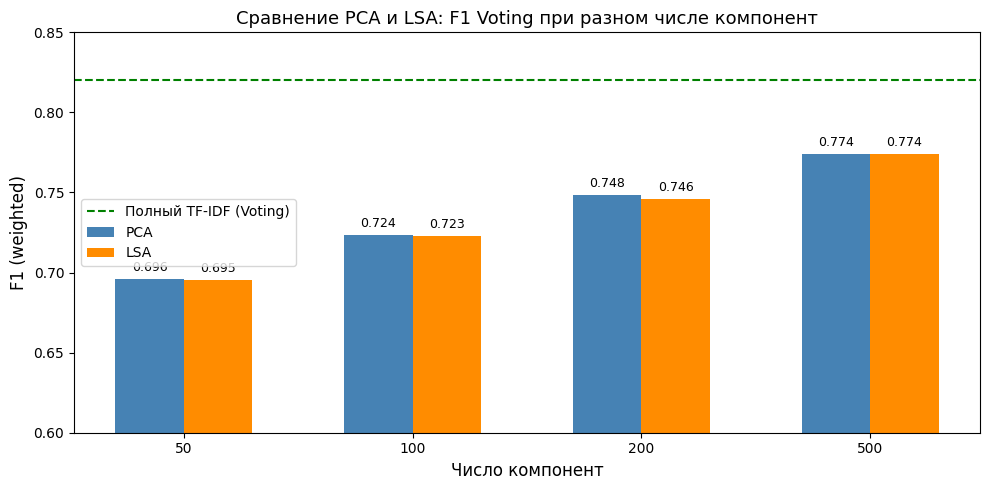

In [64]:
fig, ax = plt.subplots(figsize=(10, 5))

comps = [50, 100, 200, 500]

pca_f1 = [pca_df[pca_df['Компоненты'] == n]['F1 Voting'].values[0] for n in comps]
lsa_f1 = [lsa_df[lsa_df['Компоненты'] == n]['F1 Voting'].values[0] for n in comps]

x = np.arange(len(comps))
width = 0.3

bars1 = ax.bar(x - width/2, pca_f1, width, label='PCA', color='steelblue')
bars2 = ax.bar(x + width/2, lsa_f1, width, label='LSA', color='darkorange')

ax.axhline(y=f1_vot, color='green', linestyle='--', linewidth=1.5, label='Полный TF-IDF (Voting)')

ax.set_xlabel('Число компонент', fontsize=12)
ax.set_ylabel('F1 (weighted)', fontsize=12)
ax.set_title('Сравнение PCA и LSA: F1 Voting при разном числе компонент', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(comps)
ax.legend()
ax.set_ylim(0.6, 0.85)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 11. Итоговое сравнение моделей и визуализация результатов



На заключительном этапе сведём результаты всех обученных моделей в единую таблицу, визуализируем их и построим матрицу ошибок для лучшей модели (Voting).

In [65]:
all_results = pd.DataFrame([
    {'Модель': 'Decision Tree',        'F1': results[results['model'] == 'Decision Tree']['test_f1'].values[0], 'Тип': 'Дерево'},
    {'Модель': 'kNN',                  'F1': results[results['model'] == 'kNN']['test_f1'].values[0], 'Тип': 'На основе расстояний'},
    {'Модель': 'Gradient Boosting',    'F1': results[results['model'] == 'Gradient Boosting']['test_f1'].values[0], 'Тип': 'Ансамбль (бустинг)'},
    {'Модель': 'Random Forest',        'F1': results[results['model'] == 'Random Forest']['test_f1'].values[0], 'Тип': 'Ансамбль (бэггинг)'},
    {'Модель': 'Perceptron',           'F1': results[results['model'] == 'Perceptron']['test_f1'].values[0], 'Тип': 'Линейная'},
    {'Модель': 'Naive Bayes',          'F1': results[results['model'] == 'Naive Bayes']['test_f1'].values[0], 'Тип': 'Вероятностная'},
    {'Модель': 'SVM',                  'F1': results[results['model'] == 'SVM']['test_f1'].values[0], 'Тип': 'Линейная'},
    {'Модель': 'Logistic Regression',  'F1': results[results['model'] == 'Logistic Regression']['test_f1'].values[0], 'Тип': 'Линейная'},
    {'Модель': 'Ridge Classifier',     'F1': results[results['model'] == 'Ridge Classifier']['test_f1'].values[0], 'Тип': 'Линейная'},
    {'Модель': 'SGD',                  'F1': results[results['model'] == 'SGD']['test_f1'].values[0], 'Тип': 'Линейная'},
    {'Модель': 'Stacking',            'F1': f1_stack, 'Тип': 'Ансамбль (стекинг)'},
    {'Модель': 'SGD + class_weight',   'F1': f1_bal_sgd, 'Тип': 'Линейная'},
    {'Модель': 'Voting (hard)',        'F1': f1_vot, 'Тип': 'Ансамбль (голосование)'},
]).sort_values(by='F1', ascending=False)

all_results

,Модель,F1,Тип
12,Voting (hard),0.820204,Ансамбль (голосование)
10,Stacking,0.820177,Ансамбль (стекинг)
11,SGD + class_weight,0.819911,Линейная
9,SGD,0.817869,Линейная
8,Ridge Classifier,0.815533,Линейная
7,Logistic Regression,0.807441,Линейная
6,SVM,0.805133,Линейная
5,Naive Bayes,0.781390,Вероятностная
4,Perceptron,0.758041,Линейная
3,Random Forest,0.729042,Ансамбль (бэггинг)


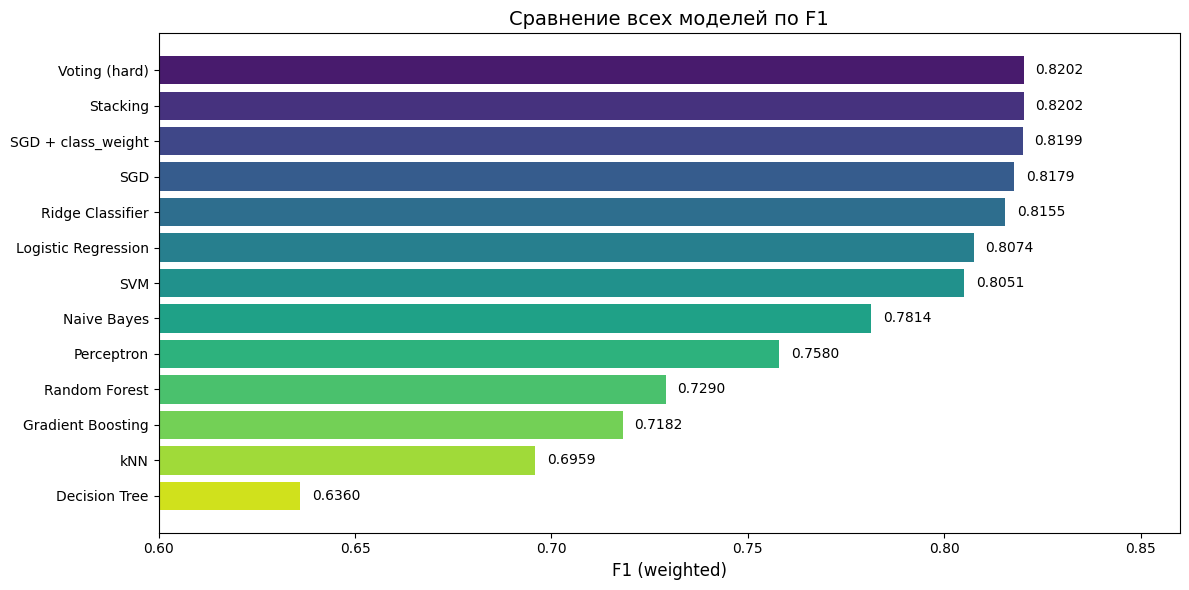

In [66]:
fig, ax = plt.subplots(figsize=(12, 6))

palette = sns.color_palette('viridis', n_colors=len(all_results))

bars = ax.barh(all_results['Модель'], all_results['F1'], color=palette)

for bar, val in zip(bars, all_results['F1']):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2, f'{val:.4f}',
            va='center', fontsize=10)

ax.set_xlabel('F1 (weighted)', fontsize=12)
ax.set_title('Сравнение всех моделей по F1', fontsize=14)
ax.set_xlim(0.6, 0.86)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Также посмотрим на матрицу ошибок и classification report по итоговой модели.

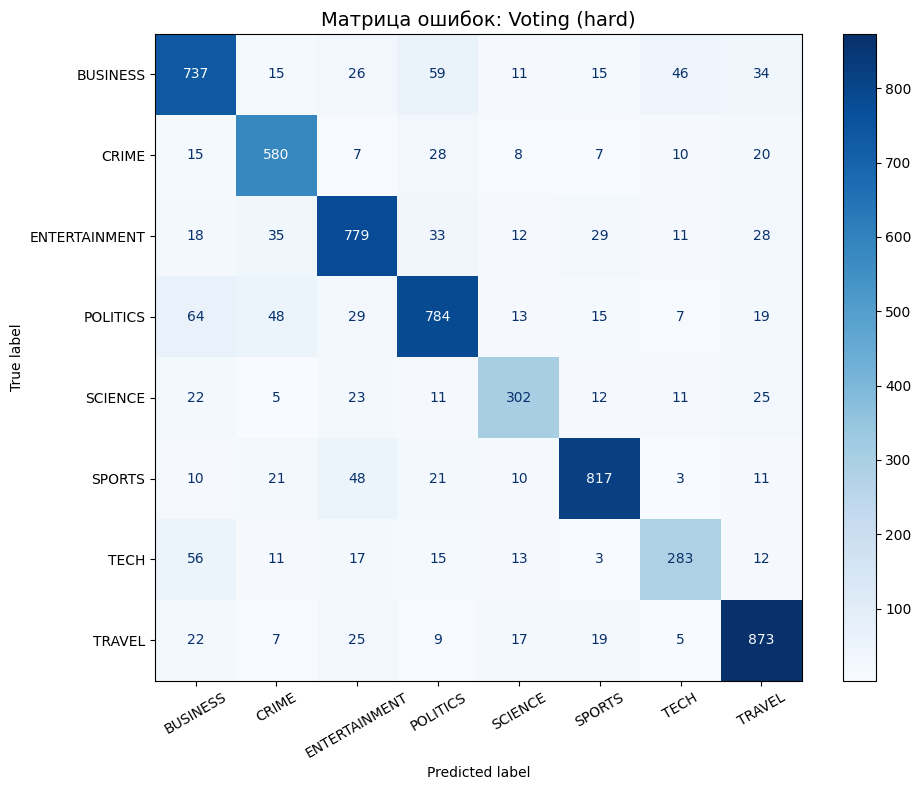

In [67]:
y_pred_best = voting.predict(X_test_tfidf)

fig, ax = plt.subplots(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred_best, labels=sorted(y_test.unique()))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y_test.unique()))
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Матрица ошибок: Voting (hard)', fontsize=14)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [68]:
print(classification_report(y_test, y_pred_best))

               precision    recall  f1-score   support

     BUSINESS       0.78      0.78      0.78       943
        CRIME       0.80      0.86      0.83       675
ENTERTAINMENT       0.82      0.82      0.82       945
     POLITICS       0.82      0.80      0.81       979
      SCIENCE       0.78      0.73      0.76       411
       SPORTS       0.89      0.87      0.88       941
         TECH       0.75      0.69      0.72       410
       TRAVEL       0.85      0.89      0.87       977

     accuracy                           0.82      6281
    macro avg       0.81      0.81      0.81      6281
 weighted avg       0.82      0.82      0.82      6281



Лучше всего модель классифицирует категории **SPORTS** (F1 = 0.88) и **TRAVEL** (F1 = 0.87) - это категории с наиболее специфичной лексикой, что было показано ещё на этапе EDA. Также высокий результат показала категория **CRIME** (F1 = 0.83), обладающая характерной юридической и криминальной терминологией.

Наибольшие трудности вызывают категории **TECH** (F1 = 0.72) и **SCIENCE** (F1 = 0.76). Матрица ошибок показывает основные источники ошибок:
- **TECH** чаще всего путается с **BUSINESS** (56 ошибок). Это ожидаемо, поскольку новости о технологических компаниях часто пересекаются с бизнес-тематикой;
- **BUSINESS** в свою очередь ошибочно относится к **POLITICS** (59 случаев) и **TECH** (46 случаев), что объясняется пересечением лексики в темах экономической политики и новостей от корпораций;
- у **SCIENCE** ошибки распределены по нескольким категориям: чаще всего она путается с **TRAVEL** (25 ошибок), **ENTERTAINMENT** (23) и **BUSINESS** (22);
- **SPORTS** чаще всего путается с **ENTERTAINMENT** (48 ошибок), а **POLITICS** с **BUSINESS** (64) и **CRIME** (48).

Эти закономерности согласуются с результатами анализа пересечения словарей (матрица Жаккара): пары классов с наибольшим лексическим перекрытием действительно показывают наибольшее число взаимных ошибок классификации. Однако ожидание из EDA о том, что SCIENCE будет классифицироваться с высоким качеством, не подтвердилось: эта категория оказалась в числе самых сложных. Вероятно, сказывается ее небольшой объем (примерно в 2 раза меньше примеров, чем у крупных классов).

В целом модель достигает accuracy = 0.82 и weighted F1 = 0.82, что является хорошим результатом для задачи классификации на 8 категорий с использованием классических методов машинного обучения.

### Заключение

В рамках проекта решена задача многоклассовой классификации новостных текстов по 8 тематическим категориям с использованием методов семантического анализа и ансамблевых моделей.

**Основные результаты:**

1. **Предобработка и векторизация.** Тексты новостей были очищены, нормализованы и представлены в виде TF-IDF матрицы (10 000 признаков, униграммы и биграммы). Балансировка классов выполнена методом undersampling, а дополнительная корректировка остаточного дисбаланса - с помощью параметра `class_weight='balanced'`.

2. **Обучение без учителя.** Анализ методами кластеризации (K-Means, агломеративная кластеризация) и визуализации (PCA 3D) показал, что без использования меток классов данные не разделяются на чёткие тематические группы. Это обосновало необходимость применения методов обучения с учителем.

3. **Сравнение моделей.** Обучено 10 моделей классификации. Линейные модели (SGD, Ridge Classifier, Logistic Regression) показали лучшие результаты (F1 = 0.81-0.82), что объясняется высокоразмерной разреженной структурой TF-IDF данных. Древесные модели и kNN оказались менее эффективными для данного типа представления.

4. **Ансамблирование.** Voting (hard) с базовыми моделями, настроенными с учётом дисбаланса классов, показал лучший результат (F1 = 0.8202), но практически сравнялся со Stacking (0.8202) и лишь немного опередил лучшую одиночную модель, SGD с учетом дисбаланса классов (0.8199). Прирост от ансамблирования оказался скромным, потому что все базовые модели линейные и ошибаются в похожих случаях.

5. **Эксперименты со снижением размерности.** Сравнение PCA и LSA показало, что оба метода дают сопоставимые результаты при одинаковом числе компонент, но ни один не превосходит полную TF-IDF матрицу. Для данной задачи обучение на полном признаковом пространстве является предпочтительным.

**Итоговая лучшая модель** - VotingClassifier (hard) на основе SGD, Ridge Classifier и Logistic Regression с F1 = 0.8202 и accuracy 0.82.